# حل متصل سیال، میدان مغناطیسی، نیرو و حرکت پارامتری ذره با PINN

این نسخه سه حل عصبی دارد: **سیال → میدان مغناطیسی → حرکت ذره**. تحریک مغناطیسی تابع زمان است. در مسیر اصلیِ حل ذره، سرعت و نیرو از شبکه‌های آموزش‌دیدهٔ سیال و مغناطیس می‌آیند. جواب‌های تحلیلیِ داخل دامنه فقط برای مقایسهٔ پس از آموزش استفاده می‌شوند.

**تعریف دقیق «کامل» در این فایل:** هر سه بخش بالا برای هندسه و فرض‌های زیر حل می‌شوند؛ حل گذرای سه‌بعدیِ عمومی، مدار سیم‌پیچ و کوپل برگشتی ذره به سیال پیاده نشده‌اند. سیال با فرض جریان کاملاً توسعه‌یافته حل می‌شود، پس معادلات ناویر–استوکس به یک مسئلهٔ شعاعی و فشار طولی کاهش می‌یابند. حل میدان در محیط یکنواختِ بدون جریان الکتریکی، با مرزهای ناشی از منابع خارجی است؛ داخل آهنربا حل نمی‌شود.

**اجرا:** Run All. تنظیم پیش‌فرض `TRAIN_FROM_SCRATCH=True` است؛ هر سه شبکه واقعاً آموزش می‌بینند. برای بازتولید سریع نتایج ذخیره‌شده، آن را `False` کنید؛ وزن‌های آموزش‌دیده داخل فایل هستند. زمان اجرای آموزش وابسته به دستگاه است. فایل‌ها در `field_solved_results` ذخیره می‌شوند.

خروجی‌های ذخیره‌شدهٔ این نوت‌بوک از بارگذاری وزن‌های آموزش‌دیده و اجرای دوبارهٔ اعتبارسنجی/کنترل به دست آمده‌اند؛ پیش‌فرضِ کد برای اجرای بعدی، آموزش از ابتدا است.

## ۱. هندسه، فرض‌ها و شرایط مرزی

| بخش | تعریف |
|---|---|
| سیال | کانال استوانه‌ای مستقیم، شعاع ۷۵ میکرومتر، طول ۱۶۰ میلی‌متر |
| خواص | نیوتنی، تراکم‌ناپذیر، ویسکوزیتهٔ مؤثر ثابت $0.003276913272$ Pa s |
| جریان | پایا، آرام، محورمتقارن، کاملاً توسعه‌یافته؛ $v_r=0$ و $\partial_zv_z=0$ |
| شرایط سیال | عدم لغزش دیواره، تقارن محور، فشار ورودیِ مشخص و فشار خروجی صفر |
| مقیاس سرعت | $U_0=0.03$ m/s؛ افت فشار $\Delta p=4\eta U_0L/R_v^2$ |
| منابع مغناطیسی | مقطعِ دو استوانهٔ بی‌نهایت‌طول در جهت عمود بر صفحه، شعاع ۲۰ mm، مرکز $x=\pm40$ mm و $z=0$ |
| دامنهٔ میدان | $(x/d,z/d)\in[-0.4,0.4]\times[-2.4,2.4]$؛ منابع بیرون آن هستند |
| مرز مغناطیسی | پتانسیل معلوم روی چهار ضلع؛ دادهٔ منبع استوانه‌ای خارجی، نه برچسبِ داخل دامنه |
| محیط مغناطیسی | $\mu=\mu_0$ ثابت؛ ذره میدان اعمال‌شده را تغییر نمی‌دهد |
| ذره | کروی با شعاع ۵۰۰ nm، رهاسازی $x=0,z=-80$ mm، پاسخ القایی غیر اشباع |
| حرکت | حد بیش‌میرا با مقاومت استوکس؛ اینرسی، براونی، گرانش و برخورد حذف شده‌اند |
| تحریک | پنج ضریب در $[-0.5,0.5]$؛ فقط یک منبع در هر لحظه فعال است |
| زمان و حاشیه | $\tau\in[0,3.8]$، حدود ۵٫۰۶۷ s؛ ارزیابی نیرو برای $|X|\le0.8, |Z|\le2$ |
| کوپل | سیال و میدان → ذره؛ واکنش ذره روی سیال و برهم‌کنش ذرات حذف شده‌اند |

برای چگالی مرجع ذره $5000$ kg/m³ (صرفاً جهت بررسی تقریب)، زمان آرامش استوکس $2\rho_pR_p^2/(9\eta)$ حدود $8.48\times10^{-8}$ ثانیه است؛ حذف اینرسی برای تحریک‌های آهستهٔ چندثانیه‌ای انتخاب شده است.

نقطهٔ کار فشار از مقیاس سرعتِ فایل قبلی انتخاب شده است؛ برای کانال ایدئال، حل مرجع میانگین ۱۵ mm/s دارد. تغییر هندسه/فشار/خواص/افق نیازمند آموزش مجدد است. «نیروی متغیر با زمان» به معنای حل مدار یا تأخیر منبع نیست: تقریب شبه‌ساکن و منبع ایدئال به کار می‌رود. شرط غیر اشباع در هر بازپخش نیز کنترل می‌شود.

## ۲. معادلاتی که واقعاً حل می‌شوند

**سیال.** از $\nabla\!\cdot\mathbf v=0$ و ناویر–استوکس پایا، با فرض‌های بالا:

$$\partial_rp=0,\qquad \eta\frac1r\partial_r(r\partial_rv_z)-\partial_zp=0.$$

با $q=(r/R_v)^2$, $\xi=(z-z_{in})/L$, $w=v_z/U_0$ و $P=p/\Delta p$، باقیماندهٔ آموزش برابر است با:

$$q\,w_{qq}+w_q-P_\xi=0.$$

دو تابع مجهولِ شبکه‌ای $w(q)$ و $P(\xi)$ هستند. $w(1)=0$, $P(0)=1$, $P(1)=0$ سخت اعمال می‌شوند؛ تقارن و منظم‌بودن محور با استفاده از $q$ برقرار است. پروفایل سهموی به‌عنوان خروجیِ معلوم به ذره داده نمی‌شود. این کاهش، فرض جریان کاملاً توسعه‌یافته را حذف نمی‌کند.

**مغناطیس.** در ناحیهٔ بدون جریان و با تراوایی ثابت:

$$\mathbf H=-\nabla\Phi,\quad\mathbf B=\mu_0\mathbf H,\quad\nabla^2\Phi=0.$$

شبکه پتانسیلِ بی‌بعد $\phi(\hat x,Z)$ را با کمینه‌کردن $\phi_{\hat x\hat x}+\phi_{ZZ}$ یاد می‌گیرد. مرز چپ از $\phi_b=(\hat x+1)/[(\hat x+1)^2+Z^2]$ تأمین می‌شود. یک درون‌یابی Coons فقط داده‌های چهار ضلع را به داخل امتداد می‌دهد؛ تصحیح عصبی، حل لاپلاس را تعیین می‌کند. مرز راست با تقارن آینه‌ای حل چپ به دست می‌آید.

$$B_0=\frac{\mu_0M_sR_{mag}^2}{2d^2},\quad \mathbf b=-\nabla\phi,\quad
\mathbf F_m=\frac{\alpha B_0^2}{d}\frac12\nabla |\mathbf b|^2,\quad \alpha=\frac{3V_p}{\mu_0}.$$

نیرو به مشتق دوم پتانسیل وابسته است؛ بنابراین دقت میدان **و نیرو** جدا آزموده می‌شود. برای سرعت آموزش ذره، نیروهای حاصل از شبکهٔ مغناطیس با چندجمله‌ای‌های چبیشف فشرده می‌شوند؛ خطای این فشرده‌سازی نیز مستقل بررسی می‌شود. جدول نیرو از جواب تحلیلی پر نمی‌شود.

**تحریک و ذره.** $u(s)=\sum a_k B_k^4(s)$ و $s=\tau/T$؛ دامنهٔ منبع چپ $\sqrt{\max(-u,0)}$ و راست $\sqrt{\max(u,0)}$ است. با $X=x/R_v$ و $Z=z/d$:

$$6\pi\eta R_p(\dot{\mathbf r}_p-\mathbf v_f)=\mathbf F_m.$$

هر دو مؤلفهٔ نیروی مغناطیسی، از جمله رانش مغناطیسیِ طولی، حفظ می‌شوند. نیروی استوکس در این حد برابر $-\mathbf F_m$ است. شبکهٔ ذره $(s,a_0,\ldots,a_4)\mapsto(X,Z)$ را یاد می‌گیرد. شرط اولیه سخت است و برچسب مسیر عددی به آموزش آن داده نمی‌شود.

In [1]:
import importlib.util
missing=[m for m in ['torch','numpy','scipy','matplotlib','IPython'] if importlib.util.find_spec(m) is None]
if missing: raise ImportError('Install with: %pip install torch numpy "scipy>=1.12" matplotlib ipython; restart and Run All. Missing: '+str(missing))
import matplotlib.pyplot as plt
from IPython.display import display,Markdown


In [2]:
"""Parameter-conditioned, residual-only PINN and bounded magnetic trajectory control.

The validated source notebook supplies the reduced one-way particle equations.
This file adds a bounded *effective signed force* input; it is not Maxwell/coil CFD.
No ODE trajectory or target path is used to train the forward PINN.
"""
from dataclasses import dataclass, asdict
from pathlib import Path
import json
import math
import time
import numpy as np
import torch
from torch import nn


@dataclass(frozen=True)
class Config:
    # Fixed physical parameters: only the magnetic waveform varies in this stage.
    mu0: float = 4 * math.pi * 1e-7
    Ms: float = 1e6
    Msp: float = 4.78e5
    Rmag: float = 0.02
    Rv: float = 75e-6
    rp: float = 500e-9
    mean: float = 0.015
    eta: float = 0.003276913272013514
    beta: float = 1.0
    X0: float = 0.0
    Z0: float = -2.0
    T: float = 4.0  # dimensionless horizon tau; physical time is tau*d/(2*mean)
    umax: float = 0.5
    K: int = 5      # degree-four Bernstein waveform, five bounded coefficients
    width: int = 64
    depth: int = 3
    seed: int = 42

    @property
    def d(self):
        return (1 + self.beta) * self.Rmag

    @property
    def time_scale(self):
        return self.d / (2 * self.mean)

    @property
    def C(self):
        return self.mu0 * self.rp**2 * 3 * self.Ms**2 / (
            18 * self.eta * self.Rv * self.mean * (1 + self.beta)**4)

    @property
    def drag(self):
        return 6 * math.pi * self.eta * self.rp


def bernstein(s, K):
    """s: [N,1], result [N,K], partition of unity on [0,1]."""
    return torch.cat([math.comb(K-1,k) * s**k * (1-s)**(K-1-k)
                      for k in range(K)], dim=1)


def waveform(s, a):
    """a are signed force coefficients, not signed magnetic field strengths."""
    return (bernstein(s, a.shape[1]) * a).sum(dim=1, keepdim=True)


def waveform_numpy(s, a):
    a = np.asarray(a, dtype=float)
    s = np.atleast_1d(s).astype(float)
    b = np.column_stack([math.comb(len(a)-1,k) * s**k * (1-s)**(len(a)-1-k)
                         for k in range(len(a))])
    return b @ a


class ParametricPINN(nn.Module):
    """A single shared network: (s, a0,...,a4) -> (X,Z)."""
    def __init__(self, cfg=Config()):
        super().__init__()
        self.cfg = cfg
        layers = []
        n = cfg.K + 1
        for _ in range(cfg.depth):
            layers += [nn.Linear(n, cfg.width), nn.Tanh()]
            n = cfg.width
        layers += [nn.Linear(n, 2)]
        self.net = nn.Sequential(*layers)
        for layer in self.net:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)
                nn.init.zeros_(layer.bias)
        nn.init.zeros_(self.net[-1].weight)

    def forward(self, s, a):
        c = self.cfg
        h = self.net(torch.cat((2*s-1, a/c.umax), dim=1))
        # Exact fixed release; the baseline is unforced prescribed Poiseuille flow.
        return torch.cat((c.X0+s*h[:,0:1], c.Z0+c.T*s+s*h[:,1:2]), dim=1)


def residual(model, s, a, create_graph=True):
    c = model.cfg
    q = model(s,a)
    dx = torch.autograd.grad(q[:,0].sum(),s,create_graph=create_graph,retain_graph=True)[0]/c.T
    dz = torch.autograd.grad(q[:,1].sum(),s,create_graph=create_graph,retain_graph=True)[0]/c.T
    rx = dx - c.C*waveform(s,a)/(1+q[:,1:2]**2)**3
    rz = dz - (1-q[:,0:1]**2)
    return torch.cat((rx,rz), dim=1)


def train(cfg=Config(), adam_steps=6000, lbfgs_steps=600, batch=768,
          device='cpu', verbose=True, boundary_steps=500):
    """Pure physics training. Independent references are in reference_solve only."""
    torch.set_num_threads(1)
    torch.manual_seed(cfg.seed)
    model = ParametricPINN(cfg).to(device=device,dtype=torch.float64)
    sampler = torch.quasirandom.SobolEngine(cfg.K+1,scramble=True,seed=cfg.seed)
    optimizer = torch.optim.Adam(model.parameters(),lr=0.002)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,adam_steps,eta_min=0.0001)
    history=[]
    tic=time.perf_counter()
    for step in range(adam_steps):
        points=sampler.draw(batch).to(device=device,dtype=torch.float64)
        s=points[:,0:1].detach().requires_grad_(True)
        a=cfg.umax*(2*points[:,1:]-1)
        # Include coefficient-domain faces, constant controls and the no-field case.
        a[:batch//8]=torch.sign(a[:batch//8])*cfg.umax
        a[batch//8:batch//4]=a[batch//8:batch//4,0:1]
        a[batch//4:batch//4+8]=0
        optimizer.zero_grad(set_to_none=True)
        r=residual(model,s,a)
        loss=(r*r).mean()
        loss.backward()
        optimizer.step()
        scheduler.step()
        if step%1000==0 or step==adam_steps-1:
            value=float(loss.detach())
            history.append(dict(stage='adam',step=step+1,loss=value))
            if verbose: print(f'Adam {step+1}/{adam_steps}: residual MSE={value:.3e}',flush=True)
    # Fixed collocation set for deterministic L-BFGS. No solution labels.
    points=sampler.draw(6144).to(device=device,dtype=torch.float64)
    s=points[:,0:1].detach().requires_grad_(True)
    a=cfg.umax*(2*points[:,1:]-1)
    a[:768]=torch.sign(a[:768])*cfg.umax
    a[768:1280]=a[768:1280,0:1]
    a[1280:1312]=0
    optimizer=torch.optim.LBFGS(model.parameters(),lr=1.0,max_iter=lbfgs_steps,
        tolerance_grad=1e-10,tolerance_change=1e-13,history_size=40,line_search_fn='strong_wolfe')
    calls=[0]
    def closure():
        optimizer.zero_grad(set_to_none=True)
        if s.grad is not None: s.grad=None
        r=residual(model,s,a)
        loss=(r*r).mean()
        loss.backward()
        calls[0]+=1
        if verbose and calls[0]%200==0:
            print(f'L-BFGS closure {calls[0]}: residual MSE={float(loss.detach()):.3e}',flush=True)
        return loss
    optimizer.step(closure)
    final=float((residual(model,s,a)**2).mean().detach())
    history.append(dict(stage='lbfgs',step=calls[0],loss=final))
    metadata=dict(config=asdict(cfg),seconds=time.perf_counter()-tic,history=history,
        training='ODE residuals + hard fixed initial conditions only; no solve_ivp or target trajectories',
        settings=dict(adam_steps=adam_steps,lbfgs_steps=lbfgs_steps,batch=batch,lbfgs_points=6144),
        device=device,dtype='float64')
    if boundary_steps:
        refinement=boundary_refine(model,steps=boundary_steps,verbose=verbose)
        metadata['history'].append(refinement)
        metadata['settings']['boundary_steps']=boundary_steps
        metadata['seconds']=time.perf_counter()-tic
    model.eval()
    return model,metadata


def boundary_refine(model,steps=500,verbose=True):
    """Residual-only refinement on systematic control-domain boundaries.

    These are collocation constraints, never reference-solution observations.
    """
    from itertools import product
    c=model.cfg
    device=next(model.parameters()).device
    dtype=next(model.parameters()).dtype
    base=torch.quasirandom.SobolEngine(c.K+1,scramble=True,seed=c.seed+190).draw(3072).to(device=device,dtype=dtype)
    controls=np.array(list(product([-c.umax,c.umax],repeat=c.K)))
    controls=np.vstack((controls,np.repeat(np.linspace(-c.umax,c.umax,9)[:,None],c.K,axis=1)))
    grid=(np.arange(97)+.319)/97
    ss=torch.tensor(np.tile(grid,len(controls))[:,None],dtype=dtype,device=device)
    aa=torch.tensor(np.repeat(controls,len(grid),axis=0),dtype=dtype,device=device)
    s=torch.cat((base[:,0:1],ss)).detach().requires_grad_(True)
    a=torch.cat((c.umax*(2*base[:,1:]-1),aa))
    opt=torch.optim.LBFGS(model.parameters(),lr=1,max_iter=steps,line_search_fn='strong_wolfe',
        tolerance_grad=2e-11,tolerance_change=1e-14,history_size=50)
    calls=[0]
    def closure():
        opt.zero_grad(set_to_none=True)
        if s.grad is not None: s.grad=None
        r=residual(model,s,a)
        loss=(r*r).mean()
        loss.backward()
        calls[0]+=1
        if verbose and calls[0]%200==0:
            print(f'Boundary refinement {calls[0]}: residual MSE={float(loss.detach()):.3e}',flush=True)
        return loss
    opt.step(closure)
    return dict(stage='boundary_lbfgs',calls=calls[0],loss=float((residual(model,s,a)**2).mean().detach()),
                points=len(s),control_data='PDE/ODE collocation only')


def check_coefficients(a,cfg):
    a=np.asarray(a,dtype=float)
    if a.shape != (cfg.K,) or not np.all(np.isfinite(a)):
        raise ValueError(f'Expected {cfg.K} finite coefficients.')
    if np.max(np.abs(a))>cfg.umax+1e-12:
        raise ValueError('Magnetic coefficients outside the trained domain; retraining is required.')
    return a


def predict(model,a,t_seconds,physical=True):
    c=model.cfg
    a=check_coefficients(a,c)
    tt=np.atleast_1d(t_seconds).astype(float)
    if not np.all(np.isfinite(tt)) or np.any(tt<0) or np.any(tt>c.T*c.time_scale+1e-12):
        raise ValueError('Time outside the trained pre-event horizon.')
    device=next(model.parameters()).device
    s=torch.tensor(tt[:,None]/(c.T*c.time_scale),dtype=torch.float64,device=device)
    aa=torch.tensor(a,dtype=torch.float64,device=device)[None].expand(len(tt),-1)
    with torch.no_grad(): q=model(s,aa).cpu().numpy()
    # The exact axial solution obeys Z <= Z0+tau <= 2 on this fixed horizon.
    # A small surrogate error near the endpoint is assessed by validation, not
    # mistaken for an actual outlet event in the exactly unforced case.
    if np.any(np.abs(q[:,0])>=1):
        raise RuntimeError('Predicted wall event; post-event motion is outside this model.')
    return q*np.array([c.Rv,c.d]) if physical else q




In [3]:
"""Solved fully-developed cylindrical flow, solved exterior magnetic potential,
and a parameter-conditioned particle PINN. One-way field-to-particle coupling.
Requires the definitions in parametric_magnetic_pinn.py in the same namespace.
"""
from numpy.polynomial import chebyshev as cheb
from scipy.integrate import solve_ivp
from scipy.optimize import minimize, lsq_linear

class SmallNet(nn.Module):
    def __init__(self,inputs,width=40,depth=3):
        super().__init__()
        layers=[]
        for _ in range(depth):
            layers += [nn.Linear(inputs,width),nn.Tanh()];inputs=width
        layers += [nn.Linear(width,1)]
        self.net=nn.Sequential(*layers)
        for l in self.net:
            if isinstance(l,nn.Linear):nn.init.xavier_normal_(l.weight);nn.init.zeros_(l.bias)
    def forward(self,x):return self.net(x)

def grad(y,x):
    return torch.autograd.grad(y.sum(),x,create_graph=True,retain_graph=True)[0]

class FluidPINN(nn.Module):
    def __init__(self):
        super().__init__();self.velocity=SmallNet(1,16,2);self.pressure=SmallNet(1,16,2)
    def w(self,q):return (1-q)*self.velocity(2*q-1)
    def p(self,xi):return 1-xi+xi*(1-xi)*self.pressure(2*xi-1)
    def equation(self,points):
        q=points[:,0:1].detach().requires_grad_(True)
        xi=points[:,1:2].detach().requires_grad_(True)
        w=self.w(q);wq=grad(w,q)
        return q*grad(wq,q)+wq-grad(self.p(xi),xi)

def boundary_phi(x,z):
    # Exterior cylindrical-source potential, used on the computational boundary ONLY.
    return (x+1)/((x+1)**2+z*z)

class MagneticPINN(nn.Module):
    ax=.4;az=2.4
    def __init__(self):super().__init__();self.correction=SmallNet(2,40,3)
    def forward(self,points):
        x=points[:,0:1];z=points[:,1:2];a=x/self.ax;b=z/self.az
        l=(1-a)/2;r=(1+a)/2;bot=(1-b)/2;top=(1+b)/2
        # Coons lifting: boundary data only; this is not the interior analytic solution.
        lift=l*boundary_phi(-self.ax,z)+r*boundary_phi(self.ax,z)
        lift+=bot*boundary_phi(x,-self.az)+top*boundary_phi(x,self.az)
        corners=l*(bot*boundary_phi(-self.ax,-self.az)+top*boundary_phi(-self.ax,self.az))
        corners+=r*(bot*boundary_phi(self.ax,-self.az)+top*boundary_phi(self.ax,self.az))
        return lift-corners+(1-a*a)*(1-b*b)*self.correction(torch.cat((a,b),1))
    def equation(self,points):
        p=points.detach().requires_grad_(True)
        g=grad(self(p),p)
        return grad(g[:,0:1],p)[:,0:1]+grad(g[:,1:2],p)[:,1:2]
    def field_force(self,points):
        # B/Bscale=-grad(phi); F/(alpha*Bscale^2/d)=grad(|b|^2)/2.
        p=points.detach().requires_grad_(True)
        b=-grad(self(p),p)
        f=.5*grad((b*b).sum(1,keepdim=True),p)
        return b,f

def train_field(model,points,adam=1500,lbfgs=500,label='field'):
    model=model.double();tic=time.perf_counter()
    opt=torch.optim.Adam(model.parameters(),lr=.002)
    for j in range(adam):
        opt.zero_grad();loss=(model.equation(points)**2).mean();loss.backward();opt.step()
        if j%500==0:print(label,'Adam',j,float(loss.detach()),flush=True)
    opt=torch.optim.LBFGS(model.parameters(),max_iter=lbfgs,history_size=40,
        tolerance_grad=1e-11,tolerance_change=1e-14,line_search_fn='strong_wolfe')
    def closure():
        opt.zero_grad();loss=(model.equation(points)**2).mean();loss.backward();return loss
    opt.step(closure)
    loss=float((model.equation(points)**2).mean().detach())
    for p in model.parameters():p.requires_grad_(False)
    print(label,'finished',loss,'seconds',time.perf_counter()-tic,flush=True)
    return model,dict(loss=loss,seconds=time.perf_counter()-tic)

def analytic_magnetic(points):
    # Independent post-training reference for the prescribed exterior-source BVP.
    x,z=np.asarray(points).T;y=x+1;r2=y*y+z*z
    b=np.column_stack(((y*y-z*z)/r2**2,2*y*z/r2**2))
    f=-2*np.column_stack((y,z))/r2[:,None]**3
    return b,f

def check_fields(fluid,mag,cfg):
    rng=np.random.default_rng(72341)
    p=np.column_stack((rng.uniform(-.39,.39,2000),rng.uniform(-2.39,2.39,2000)))
    b,f=mag.field_force(torch.tensor(p,dtype=torch.float64))
    br,fr=analytic_magnetic(p)
    channel=np.column_stack((rng.uniform(-.8,.8,1200)*cfg.Rv/cfg.d,rng.uniform(-2,2,1200)))
    bc,fc=mag.field_force(torch.tensor(channel,dtype=torch.float64));bcr,fcr=analytic_magnetic(channel)
    rel=lambda x,y:float(np.linalg.norm(x-y)/np.linalg.norm(y))
    q=torch.linspace(0,1,401,dtype=torch.float64)[:,None]
    with torch.no_grad():w=fluid.w(q).numpy();pr=fluid.p(q).numpy()
    report=dict(fluid_velocity_max_error=float(abs(w-(1-q.numpy())).max()),
        fluid_pressure_max_error=float(abs(pr-(1-q.numpy())).max()),
        magnetic_B_relative_L2=rel(b.detach().numpy(),br),
        magnetic_force_relative_L2=rel(f.detach().numpy(),fr),
        channel_B_relative_L2=rel(bc.detach().numpy(),bcr),
        channel_force_relative_L2=rel(fc.detach().numpy(),fcr),
        channel_force_max_absolute=float(abs(fc.detach().numpy()-fcr).max()),
        heldout_laplace_rms=float(torch.sqrt((mag.equation(torch.tensor(p,dtype=torch.float64))**2).mean()).detach()))
    report['checks']=dict(flow_velocity=report['fluid_velocity_max_error']<.002,
        flow_pressure=report['fluid_pressure_max_error']<.002,
        B_field=report['channel_B_relative_L2']<.01,
        force_gradient=report['channel_force_relative_L2']<.02,
        laplace_residual=report['heldout_laplace_rms']<.03)
    report['all_passed']=all(report['checks'].values())
    return report

class LearnedForces:
    """Differentiable Chebyshev compression of forces from the TRAINED magnetic PINN.
    Interior analytical fields are never used to populate this approximation.
    """
    def __init__(self,mag,cfg,coeff=None):
        self.cfg=cfg
        if coeff is None:
            xx=np.cos(np.pi*(np.arange(9)+.5)/9)
            zz=np.cos(np.pi*(np.arange(129)+.5)/129)
            a,b=np.meshgrid(xx,zz,indexing='ij')
            points=np.column_stack((a.ravel()*.8*cfg.Rv/cfg.d,b.ravel()*2))
            _,f=mag.field_force(torch.tensor(points,dtype=torch.float64))
            V=cheb.chebvander2d(a.ravel(),b.ravel(),[4,48]).reshape(len(points),-1)
            self.coeff=np.linalg.lstsq(V,f.detach().numpy(),rcond=None)[0].reshape(5,49,2)
        else:self.coeff=np.asarray(coeff)
    @staticmethod
    def basis(v,n):
        terms=[torch.ones_like(v),v]
        for _ in range(2,n):terms.append(2*v*terms[-1]-terms[-2])
        return torch.cat(terms[:n],dim=1)
    def torch(self,X,Z):
        cx=self.basis(X/.8,5);cz=self.basis(Z/2,49)
        coef=torch.tensor(self.coeff,dtype=X.dtype,device=X.device)
        return torch.einsum('ni,nj,ijk->nk',cx,cz,coef)
    def numpy(self,X,Z):
        return np.array([cheb.chebval2d(X/.8,Z/2,self.coeff[:,:,i]) for i in range(2)])
    def audit(self,mag):
        rng=np.random.default_rng(93220);X=rng.uniform(-.8,.8,1000);Z=rng.uniform(-2,2,1000)
        points=np.column_stack((X*self.cfg.Rv/self.cfg.d,Z))
        _,f=mag.field_force(torch.tensor(points,dtype=torch.float64))
        fitted=self.numpy(X,Z).T;err=float(abs(fitted-f.detach().numpy()).max())
        return dict(max_force_interpolation_error=err,all_passed=err<.002)

FLUID=None;FORCES=None

def full_rhs_torch(X,Z,u,c):
    # Both magnetic-force components are retained, including axial magnetic drift.
    fl=FORCES.torch(X,Z);fr=FORCES.torch(-X,Z)*torch.tensor([-1.,1.],dtype=X.dtype,device=X.device)
    f=torch.where((u>=0).expand(-1,2),fr,fl)*abs(u)
    Bscale=c.mu0*c.Ms*c.Rmag**2/(2*c.d**2)
    alpha=3*(4*math.pi*c.rp**3/3)/c.mu0
    k=alpha*Bscale**2/(c.drag*2*c.mean*c.Rv)
    return torch.cat((k*f[:,0:1],FLUID.w(X*X)+k*c.Rv/c.d*f[:,1:2]),1)

def residual(model,s,a,create_graph=True):
    q=model(s,a)
    dx=torch.autograd.grad(q[:,0].sum(),s,create_graph=create_graph,retain_graph=True)[0]/model.cfg.T
    dz=torch.autograd.grad(q[:,1].sum(),s,create_graph=create_graph,retain_graph=True)[0]/model.cfg.T
    return torch.cat((dx,dz),1)-full_rhs_torch(q[:,0:1],q[:,1:2],waveform(s,a),model.cfg)

def reference_solve(a,s,cfg=Config(),learned=False):
    """learned=True isolates particle-PINN error; False audits the entire field chain."""
    a=check_coefficients(a,cfg)
    Bscale=cfg.mu0*cfg.Ms*cfg.Rmag**2/(2*cfg.d**2)
    alpha=3*(4*math.pi*cfg.rp**3/3)/cfg.mu0
    k=alpha*Bscale**2/(cfg.drag*2*cfg.mean*cfg.Rv)
    def rhs(tau,q):
        X,Z=q;u=float(waveform_numpy(tau/cfg.T,a)[0]);side=1 if u<0 else -1
        if learned:
            f=FORCES.numpy(side*X,Z)*np.array([side,1])
            with torch.no_grad():w=float(FLUID.w(torch.tensor([[X*X]],dtype=torch.float64))[0,0])
        else:
            _,fa=analytic_magnetic([[side*X*cfg.Rv/cfg.d,Z]])
            f=fa[0]*[side,1];w=1-X*X
        return [k*abs(u)*f[0],w+k*cfg.Rv/cfg.d*abs(u)*f[1]]
    def wall(t,q):return .8-abs(q[0])
    wall.terminal=True;wall.direction=-1
    sol=solve_ivp(rhs,[0,cfg.T],[cfg.X0,cfg.Z0],rtol=1e-10,atol=1e-12,
        method='DOP853',dense_output=True,max_step=.04,events=wall)
    if not sol.success or sol.t[-1]<cfg.T-1e-8:raise RuntimeError('Trajectory outside the declared field/particle domain.')
    return sol.sol(np.asarray(s)*cfg.T).T

def validate_full(model,n=32,seed=92731):
    c=model.cfg;rng=np.random.default_rng(seed);s=np.linspace(0,1,201)
    controls=np.vstack((rng.uniform(-c.umax,c.umax,(n,c.K)),
        np.full((1,c.K),-.5),np.full((1,c.K),.5),np.zeros((1,c.K))))
    rows=[]
    for a in controls:
        pred=predict(model,a,s*c.T*c.time_scale,False)
        oracle=reference_solve(a,s,c)
        learned=reference_solve(a,s,c,learned=True)
        rows.append(dict(coefficients=a.tolist(),
            end_to_end_max_X_Rv=float(abs(pred[:,0]-oracle[:,0]).max()),
            end_to_end_max_Z_d=float(abs(pred[:,1]-oracle[:,1]).max()),
            particle_only_max_X_Rv=float(abs(pred[:,0]-learned[:,0]).max()),
            particle_only_max_Z_d=float(abs(pred[:,1]-learned[:,1]).max())))
    p=torch.quasirandom.SobolEngine(c.K+1,scramble=True,seed=seed+1).draw(4096).double()
    st=p[:,0:1].detach().requires_grad_(True);a=(2*p[:,1:]-1)*c.umax
    rr=residual(model,st,a,False).detach().numpy()
    r=dict(n_cases=len(rows),cases=rows,residual_rms=float(np.sqrt(np.mean(rr**2))))
    r['max_X_Rv']=max(v['end_to_end_max_X_Rv'] for v in rows)
    r['max_Z_d']=max(v['end_to_end_max_Z_d'] for v in rows)
    r['checks']=dict(end_to_end_X=r['max_X_Rv']<.01,end_to_end_Z=r['max_Z_d']<.01,
        residual=r['residual_rms']<.003)
    r['all_passed']=all(r['checks'].values())
    return r

def track_x(model,s,desired_X):
    """Optimize transverse target; axial timing is an output of solved dynamics."""
    c=model.cfg;s=np.asarray(s);target=np.asarray(desired_X)
    if target.shape!=s.shape or abs(target[0]-c.X0)>1e-9 or max(abs(target))>=.7:
        raise ValueError('Bad target shape, release point or wall margin.')
    st=torch.tensor(s[:,None],dtype=torch.float64);tar=torch.tensor(target[:,None],dtype=torch.float64)
    nominal=c.Z0+c.T*s
    req=np.gradient(target,s)/c.T*(1+nominal**2)**3/c.C
    B=bernstein(st,c.K).numpy()
    initial=lsq_linear(B,req,bounds=(-c.umax,c.umax)).x
    states=[p.requires_grad for p in model.parameters()]
    for p in model.parameters():p.requires_grad_(False)
    def obj(a):
        at=torch.tensor(a,dtype=torch.float64,requires_grad=True)
        q=model(st,at[None].expand(len(s),-1))
        loss=((q[:,0:1]-tar)**2).mean()+1e-8*((at[1:]-at[:-1])**2).mean()
        g=torch.autograd.grad(loss,at)[0]
        return float(loss.detach()),g.detach().numpy()
    try:opt=minimize(obj,initial,jac=True,bounds=[(-c.umax,c.umax)]*c.K,
        method='L-BFGS-B',options=dict(maxiter=400,ftol=1e-15,gtol=1e-10))
    finally:
        for p,state in zip(model.parameters(),states):p.requires_grad_(state)
    pred=predict(model,opt.x,s*c.T*c.time_scale,False);replay=reference_solve(opt.x,s,c)
    error=float(abs(replay[:,0]-target).max())
    return dict(coefficients=opt.x.tolist(),target_X=target,prediction=pred,replay=replay,
        u=waveform_numpy(s,opt.x),max_tracking_error_Rv=error,
        accepted=bool(opt.success and error<.01),message=str(opt.message))

def force_table(cfg,a,s,q):
    u=waveform_numpy(s,a);side=np.where(u<0,1.,-1.)
    f=FORCES.numpy(side*q[:,0],q[:,1]).T*np.column_stack((side,np.ones(len(s))))*abs(u[:,None])
    bs=cfg.mu0*cfg.Ms*cfg.Rmag**2/(2*cfg.d**2)
    alpha=3*(4*math.pi*cfg.rp**3/3)/cfg.mu0
    F=alpha*bs**2/cfg.d*f
    # Overdamped model: drag balances magnetic force in both components.
    return np.column_stack((s*cfg.T*cfg.time_scale,q[:,0]*cfg.Rv,q[:,1]*cfg.d,u,F,-F))


## ۳. وزن‌های ثبت‌شده و انتخاب اجرای آموزش

محتوای سلول فشردهٔ زیر فقط وزن‌ها و گزارش آموزش است. حالت `True` به این وزن‌ها متکی نیست. برای ثابت‌بودن مرجع آموزشی از CPU و float64 استفاده شده است؛ پورت CUDA در این فایل آزموده نشده است.

In [4]:
FIELD_WEIGHTS='''...'''
PARTICLE_WEIGHTS='''...'''

In [5]:
import io,base64
OUT=Path('field_solved_results');OUT.mkdir(exist_ok=True)
TRAIN_FROM_SCRATCH=True
CFG=Config(T=3.8)
torch.set_num_threads(1);torch.manual_seed(98)
if TRAIN_FROM_SCRATCH:
    fp=torch.quasirandom.SobolEngine(2,scramble=True,seed=10).draw(256).double()
    FLUID,fluid_training=train_field(FluidPINN(),fp,adam=700,lbfgs=150,label='fluid')
    mp=torch.quasirandom.SobolEngine(2,scramble=True,seed=11).draw(1536).double()
    mp=(2*mp-1)*torch.tensor([.4,2.4])
    MAG,magnetic_training=train_field(MagneticPINN(),mp,adam=2500,lbfgs=900,label='magnetic')
    FORCES=LearnedForces(MAG,CFG)
else:
    ck=torch.load(io.BytesIO(base64.b64decode(FIELD_WEIGHTS)),weights_only=True)
    if ck['config']!=asdict(CFG):raise ValueError('Configuration differs from saved field weights; retrain.')
    FLUID=FluidPINN().double();FLUID.load_state_dict(ck['fluid'])
    MAG=MagneticPINN().double();MAG.load_state_dict(ck['magnetic'])
    for m in [FLUID,MAG]:
        for p in m.parameters():p.requires_grad_(False)
    FORCES=LearnedForces(MAG,CFG,ck['coefficients'])
    fluid_training=ck['fluid_training'];magnetic_training=ck['magnetic_training']
    print('Loaded trained FLUID and MAGNETIC weights; no field retraining in this mode.')
field_report=check_fields(FLUID,MAG,CFG)
field_report['compression']=FORCES.audit(MAG)
(OUT/'field_validation.json').write_text(json.dumps(field_report,indent=2))
print(json.dumps(field_report,indent=2))
assert field_report['all_passed'] and field_report['compression']['all_passed'], 'Field validation failed: stop before particle/control.'
torch.save(dict(fluid=FLUID.state_dict(),magnetic=MAG.state_dict(),config=asdict(CFG),coefficients=FORCES.coeff.tolist(),fluid_training=fluid_training,magnetic_training=magnetic_training),OUT/'fields.pt')


fluid Adam 0 1.7819180251343898
fluid Adam 500 0.0002115180503070842
fluid finished 5.909181450024003e-08 seconds 7.8505269470000485
magnetic Adam 0 12.038644610607042
magnetic Adam 500 0.044105540579021
magnetic Adam 1000 0.007883973571330808
magnetic Adam 1500 0.0026482569532026903
magnetic Adam 2000 0.0015215950392653685
magnetic finished 2.078130684076515e-05 seconds 122.10054636799998
{
  "fluid_velocity_max_error": 2.132947778732408e-05,
  "fluid_pressure_max_error": 1.2495576038995537e-05,
  "magnetic_B_relative_L2": 0.00041288502835335237,
  "magnetic_force_relative_L2": 0.001750667181558541,
  "channel_B_relative_L2": 0.0004840353750118951,
  "channel_force_relative_L2": 0.0028406118151555536,
  "channel_force_max_absolute": 0.008248260028228982,
  "heldout_laplace_rms": 0.0043609689823325415,
  "checks": {
    "flow_velocity": true,
    "flow_pressure": true,
    "B_field": true,
    "force_gradient": true,
    "laplace_residual": true
  },
  "all_passed": true,
  "compressio

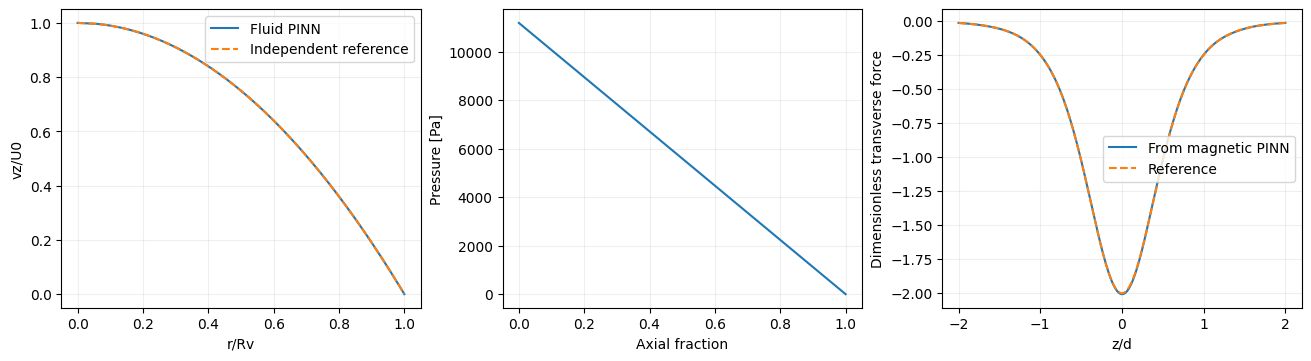

In [6]:
q=np.linspace(0,1,301);r=np.sqrt(q)
with torch.no_grad():w=FLUID.w(torch.tensor(q[:,None],dtype=torch.float64)).numpy()[:,0];pressure=FLUID.p(torch.tensor(q[:,None],dtype=torch.float64)).numpy()[:,0]
fig,axs=plt.subplots(1,3,figsize=(13,3.5),layout='constrained')
axs[0].plot(r,w,label='Fluid PINN');axs[0].plot(r,1-q,'--',label='Independent reference');axs[0].set(xlabel='r/Rv',ylabel='vz/U0');axs[0].legend()
dp=4*CFG.eta*(2*CFG.mean)*(.16)/CFG.Rv**2
axs[1].plot(q,pressure*dp);axs[1].set(xlabel='Axial fraction',ylabel='Pressure [Pa]')
z=np.linspace(-2,2,401);points=np.column_stack((np.zeros_like(z),z))
b,f=MAG.field_force(torch.tensor(points,dtype=torch.float64));br,fr=analytic_magnetic(points)
axs[2].plot(z,f[:,0].detach().numpy(),label='From magnetic PINN');axs[2].plot(z,fr[:,0],'--',label='Reference');axs[2].set(xlabel='z/d',ylabel='Dimensionless transverse force');axs[2].legend()
for ax in axs:ax.grid(alpha=.2)
fig.savefig(OUT/'field_validation.png',dpi=160);plt.show()


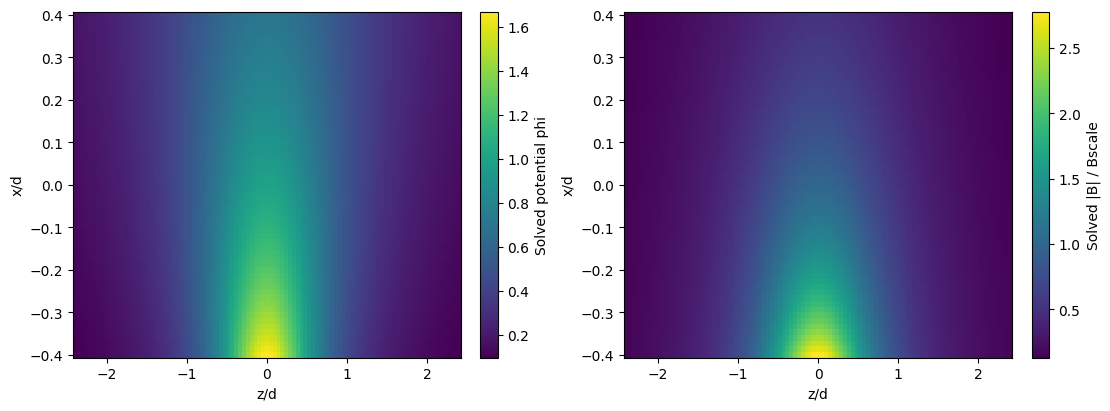

In [7]:
xx=np.linspace(-.4,.4,61);zz=np.linspace(-2.4,2.4,101)
aa,bb=np.meshgrid(xx,zz,indexing='ij');pts=torch.tensor(np.column_stack((aa.ravel(),bb.ravel())),dtype=torch.float64)
with torch.no_grad():potential=MAG(pts).numpy().reshape(aa.shape)
field,force=MAG.field_force(pts)
strength=np.linalg.norm(field.detach().numpy(),axis=1).reshape(aa.shape)
fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
im=axs[0].pcolormesh(bb,aa,potential,shading='auto');fig.colorbar(im,ax=axs[0],label='Solved potential phi')
im=axs[1].pcolormesh(bb,aa,strength,shading='auto');fig.colorbar(im,ax=axs[1],label='Solved |B| / Bscale')
for ax in axs:ax.set(xlabel='z/d',ylabel='x/d')
fig.savefig(OUT/'magnetic_spatial_fields.png',dpi=150);plt.show()


## ۴. آموزش پارامتریِ حرکت با میدان‌های حل‌شده

آموزش این مرحله از معادلات حرکت با سرعتِ شبکهٔ سیال و نیرویِ شبکهٔ مغناطیس استفاده می‌کند. نیروها در تابع `full_rhs_torch` قابل بررسی‌اند. تابع تحلیلی فقط در `reference_solve(...,learned=False)` برای ارزیابی کل زنجیره به کار می‌رود.

دو مقایسه وجود دارد: خطای شبکهٔ ذره در برابر انتگرال‌گیری با **همان میدان‌های یادگرفته‌شده**؛ و خطای کل زنجیره در برابر انتگرال‌گیری مستقل با **میدان‌های تحلیلیِ مرجع**. آستانهٔ ثبت‌شدهٔ کل زنجیره $0.01R_v$ و $0.01d$ است؛ این آستانه، ادعای دقت تجربی نیست. RMS باقیمانده باید کمتر از 0.003 باشد. حالت‌های آزمون شامل ۳۲ تحریک تصادفی مستقل و دو حد ثابت و حالت صفر است؛ ۳۵ حالت، تضمین یکنواخت کل فضای پارامترها نیست.

In [8]:
if TRAIN_FROM_SCRATCH:
    particle,particle_training=train(CFG,adam_steps=6000,lbfgs_steps=600,boundary_steps=500)
else:
    ck=torch.load(io.BytesIO(base64.b64decode(PARTICLE_WEIGHTS)),weights_only=True)
    if ck['config']!=asdict(CFG):raise ValueError('Configuration differs from particle weights; retrain.')
    particle=ParametricPINN(CFG).double();particle.load_state_dict(ck['state_dict'])
    particle_training=ck['training']
    print('Loaded trained PARTICLE weights; no particle retraining in this mode.')
particle.eval()
torch.save(dict(state_dict=particle.state_dict(),config=asdict(CFG),training=particle_training),OUT/'particle.pt')
report=validate_full(particle)
(OUT/'trajectory_validation.json').write_text(json.dumps(report,indent=2))
print(json.dumps({k:v for k,v in report.items() if k!='cases'},indent=2))
assert report['all_passed'],'End-to-end validation failed; do not accept control results.'


Adam 1/6000: residual MSE=2.828e-03
Adam 1001/6000: residual MSE=3.661e-06
Adam 2001/6000: residual MSE=1.379e-06
Adam 3001/6000: residual MSE=5.918e-07
Adam 4001/6000: residual MSE=3.094e-07
Adam 5001/6000: residual MSE=2.672e-07
Adam 6000/6000: residual MSE=2.903e-07
L-BFGS closure 200: residual MSE=1.807e-07
L-BFGS closure 400: residual MSE=1.789e-07
L-BFGS closure 600: residual MSE=1.779e-07
Boundary refinement 200: residual MSE=2.220e-07
Boundary refinement 400: residual MSE=1.652e-07
{
  "n_cases": 35,
  "residual_rms": 0.000342431717083756,
  "max_X_Rv": 0.0012110500737079633,
  "max_Z_d": 0.0024183255283782845,
  "checks": {
    "end_to_end_X": true,
    "end_to_end_Z": true,
    "residual": true
  },
  "all_passed": true
}


## ۵. مسیر هدف و کنترل تابع زمان

در این نسخه فقط مختصات عرضیِ هدف را در زمان تعیین می‌کنید؛ حرکت طولی با سرعت سیال و رانش مغناطیسیِ طولی حل می‌شود. بنابراین زمان‌بندی هر دو مختصات به‌طور مستقل تحمیل نمی‌شود. بهینه‌سازی فقط پنج ضریب تحریک را تغییر می‌دهد، نه وزن‌های سه شبکه را.

بازپخش مستقل برای هر هدف الزامی است. اگر هدف با توان و خانوادهٔ تحریک سازگار نباشد، `accepted=False` می‌شود. رسیدنِ بهینه‌ساز به توقف، به‌تنهایی به معنای رسیدن به هدف نیست. CSV نیروهای مغناطیسی و استوکس را در هر دو جهت نگه می‌دارد.

{'coefficients': [0.37501289151584377, 0.18426933943240617, 0.01319372569241943, -0.14092396838900728, -0.33842394695965006], 'max_tracking_error_Rv': 0.0003080922369847576, 'accepted': True, 'message': 'CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL'}
Maximum H/(Msp/3): 0.18994251214525662


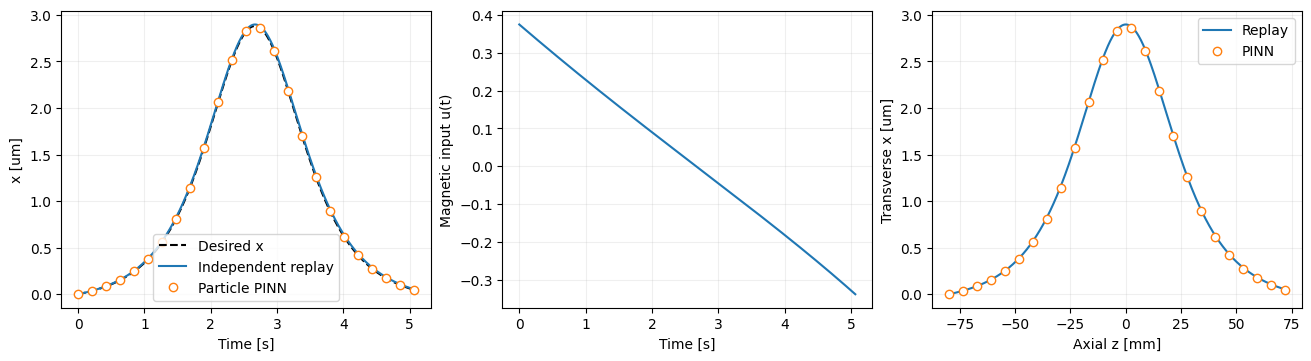

PASS: solved fields, parameter-conditioned particle motion, and independent target replay.


In [9]:
s=np.linspace(0,1,601)
def desired_X(s):
    z=CFG.Z0+CFG.T*s
    return .04*((1+z*z)**-2-(1+CFG.Z0**2)**-2)
control=track_x(particle,s,desired_X(s))
print({k:v for k,v in control.items() if k not in ['prediction','replay','target_X','u']})
a=np.asarray(control['coefficients']);replay=control['replay'];pred=control['prediction']
tab=force_table(CFG,a,s,pred)
np.savetxt(OUT/'trajectory_and_forces.csv',np.column_stack((tab,replay[:,0]*CFG.Rv,replay[:,1]*CFG.d)),delimiter=',',comments='',header='time_s,x_PINN_m,z_PINN_m,u,Fmag_at_PINN_x_N,Fmag_at_PINN_z_N,Fdrag_x_N,Fdrag_z_N,x_independent_replay_m,z_independent_replay_m')
summary={k:v for k,v in control.items() if k not in ['prediction','replay','target_X','u']}
(OUT/'control_report.json').write_text(json.dumps(summary,indent=2))
# Saturation audit along the independent physical replay, using the source reference.
side=np.where(control['u']<0,1.,-1.)
points=np.column_stack((side*replay[:,0]*CFG.Rv/CFG.d,replay[:,1]))
bref,_=analytic_magnetic(points)
Bscale=CFG.mu0*CFG.Ms*CFG.Rmag**2/(2*CFG.d**2)
H=np.linalg.norm(bref,axis=1)*Bscale/CFG.mu0*np.sqrt(abs(control['u']))
print('Maximum H/(Msp/3):',max(H)/(CFG.Msp/3))
assert max(H)<CFG.Msp/3,'Non-saturation assumption failed.'
if not control['accepted']:raise RuntimeError('Target tracking failed; inspect errors and choose a feasible path or retrain/extend the waveform family.')
fig,axs=plt.subplots(1,3,figsize=(13,3.5),layout='constrained')
axs[0].plot(s*CFG.T*CFG.time_scale,desired_X(s)*CFG.Rv*1e6,'k--',label='Desired x')
axs[0].plot(s*CFG.T*CFG.time_scale,replay[:,0]*CFG.Rv*1e6,label='Independent replay')
axs[0].plot(s[::25]*CFG.T*CFG.time_scale,pred[::25,0]*CFG.Rv*1e6,'o',mfc='white',label='Particle PINN')
axs[0].set(xlabel='Time [s]',ylabel='x [um]');axs[0].legend()
axs[1].plot(s*CFG.T*CFG.time_scale,control['u']);axs[1].set(xlabel='Time [s]',ylabel='Magnetic input u(t)')
axs[2].plot(replay[:,1]*CFG.d*1e3,replay[:,0]*CFG.Rv*1e6,label='Replay');axs[2].plot(tab[::25,2]*1e3,tab[::25,1]*1e6,'o',mfc='white',label='PINN');axs[2].legend();axs[2].set(xlabel='Axial z [mm]',ylabel='Transverse x [um]')
for ax in axs:ax.grid(alpha=.2)
fig.savefig(OUT/'control.png',dpi=160);plt.show()
print('PASS: solved fields, parameter-conditioned particle motion, and independent target replay.')


## ۶. تغییر تحریک یا مسیر و ذخیره‌سازی

برای مسیر جدید، فقط `desired_X(s)` را ویرایش و بخش کنترل را اجرا کنید. شرط `desired_X(0)=0` و افق ثابت را نگه دارید. برای تحریک دلخواه در همین خانواده، پنج ضریب را به `predict(particle,a,t_seconds)` بدهید؛ خروجی متر است. مقدار خارج از دامنهٔ ضرایب یا زمان رد می‌شود. قبول‌نشدن هدف را با افزایشِ دلخواه آستانهٔ خطا پنهان نکنید.

منبع ایدئالِ خروجی به دامنهٔ مغناطش معادل اشاره دارد؛ برای تبدیل به جریان سیم‌پیچ باید هندسه و کالیبراسیون جریان–میدان مشخص شود. ریشهٔ دوم تحریک هنگام تغییر سمت ممکن است شیب تند داشته باشد؛ محدودیت مدار، رمپ جریان و سرعت سوئیچینگ در این مدل نیست.

تمام وزن‌ها، گزارش‌های JSON، شکل‌ها و CSV در پوشهٔ خروجی ذخیره می‌شوند. اعتبارسنجیِ میدان و مسیر، عددی و نظری است. این فایل **حل دوطرفهٔ سیال–ذره نیست** و اثر غلظت ذرات بر جریان را پیش‌بینی نمی‌کند.

منابع: [Furlani & Ng, PRE 73, 061919 (2006)](https://doi.org/10.1103/PhysRevE.73.061919) برای مدل منبع استوانه‌ای، ذرهٔ القایی و استوکس؛ [Kovacs et al., Magnetostatics and micromagnetics with PINNs](https://arxiv.org/abs/2106.03362) برای حل فیزیک‌محور میدان؛ [Wang et al., Physics-informed DeepONets (2021)](https://doi.org/10.1126/sciadv.abi8605) برای ایدهٔ نگاشتِ تحریک به حل. معماری ذرهٔ حاضر MLP شرطی است، نه DeepONet.

## پیوست: نسخهٔ قبلی

کد و توضیحات نسخهٔ قبلی به‌عنوان سابقهٔ مدل کاهش‌یافته حفظ شده‌اند. اجرای آن پیش‌فرض خاموش است. نتایج آن جایگزین اعتبارسنجی نسخهٔ دارای حل میدان نیستند. فعال‌کردن پیوست نام توابع محیط را تغییر می‌دهد؛ برای برگشت، بخش‌های اصلی را دوباره اجرا کنید.

In [10]:
RUN_PREVIOUS_VERSION=False

# PINN پارامتری برای کنترل مسیر ذره با تحریک مغناطیسیِ تابع زمان

این نسخه از معادلات کاهش‌یافتهٔ فایل `Magnetic_Two_Way_Channel (2).ipynb` استفاده می‌کند. کد اعتبارسنجی اولیه در پیوست نگه داشته شده است. در این مرحله **فقط تابع تحریک مغناطیسی متغیر است**؛ مشخصات ذره، سیال، هندسه و نقطهٔ رهاسازی ثابت‌اند.

**خروجی عملی:** یک شبکهٔ مشترک برای پیش‌بینی مسیر از روی تحریک زمانی، و یک بهینه‌ساز که برای مسیر هدف جدید، ضرایب تحریک را از طریق همین شبکه تعیین می‌کند. وزن‌های شبکه برای هر هدف دوباره آموزش داده نمی‌شوند.

**اجرا:** سلول‌ها را به ترتیب اجرا کنید. وزن‌های آموزش‌دیده داخل همین فایل قرار دارند و حالت پیش‌فرض آن‌ها را بارگذاری می‌کند. برای آموزش کامل باقیمانده‌محور، `TRAIN_FROM_SCRATCH = True` بگذارید. گزارش‌ها، شکل‌ها و CSVهای حاصل در پوشهٔ `parametric_magnetic_results` نوشته می‌شوند.

**دامنهٔ فیزیکی:** جریان تجویزی و یک‌طرفه، ذرهٔ منفرد و حدّ بدون اینرسی. عنوان فایل قبلی به معنای اعتبارسنجی two-way نیست. میدان ماکسول، مدار سیم‌پیچ، اشباع گذرا، بازخورد تجربی و برهم‌کنش ذرات در این نسخه حل نمی‌شوند.

## ۱. چه چیزی به ورودی شبکه اضافه شده است؟

قرار دادن فقط $(t,B(t))$ در ورودی کافی نیست: دو تحریک می‌توانند در لحظهٔ فعلی مقدار یکسان و تا آن لحظه تاریخچهٔ متفاوت داشته باشند. اینجا **کل تابع زمانی** با پنج ضریب مشخص می‌شود:

$$s=\tau/T,\quad u(s;\mathbf a)=\sum_{k=0}^{4}a_k {4\choose k}s^k(1-s)^{4-k},\qquad a_k\in[-0.5,0.5].$$

توابع پایهٔ برنشتاین نامنفی‌اند و مجموعشان یک است؛ بنابراین کران ضرایب، $|u(s)|\le0.5$ را در تمام بازه تضمین می‌کند. این یک خانوادهٔ هموارِ درجهٔ چهار است؛ تابع دلخواه با فرکانس و پیچیدگی نامحدود را شامل نمی‌شود. افزایش `K` یا تغییر بازه به آموزش مجدد نیاز دارد.

$$\boxed{(s,a_0,a_1,a_2,a_3,a_4)\ \longmapsto\ (X_\theta,Z_\theta)}$$

این پیاده‌سازی **PINN با ورودی پارامتری** و یک MLP مشترک است، نه شبکه‌های مستقل برای هر مورد و نه معماری branch/trunk از نوع DeepONet. ایدهٔ یادگیری نگاشتِ تابع ورودی به حل، با ادبیات physics-informed operator learning مرتبط است [۲].

## ۲. معادلات و معنای متغیر مغناطیسی

همان بی‌بعدسازی فایل اصلی حفظ شده است:

$$X=x/R_v,\quad Z=z/d,\quad d=(1+\beta)R_{mag},\quad \tau=2\bar v_f t/d.$$

$$\frac{dX}{d\tau}=\frac{C\,u(\tau)}{(1+Z^2)^3},\qquad
\frac{dZ}{d\tau}=1-X^2,\qquad (X(0),Z(0))=(0,-2),$$

$$C=\frac{\mu_0 R_p^2\,3M_s^2}{18\eta R_v\bar v_f(1+\beta)^4}.$$

حالت اصلی یک آهنربا در سمت منفی $x$ داشت و با $u=-1$ بازیابی می‌شود [۱]. **این مقدار در بازهٔ آموزش نسخهٔ حاضر نیست**؛ آزمون حد ثابت این نسخه از $u=\pm0.3$ استفاده می‌کند. در حالت `single_left` فقط $u\le0$ مجاز است.

برای تغییر جهت، این نسخه یک **فرض سخت‌افزاری جدید** اضافه می‌کند: دو منبع کنترل‌پذیرِ روبه‌رو با هندسهٔ مؤثر آینه‌ای. $u$ ضریبِ نیروی مؤثر است، نه میدان مغناطیسیِ علامت‌دار. در پاسخ القاییِ غیر اشباع، نیرو با مربع دامنهٔ منبع تناسب دارد:

$$m_R=\sqrt{\max(u,0)},\qquad m_L=\sqrt{\max(-u,0)},\qquad u=m_R^2-m_L^2.$$

در هر لحظه فقط یک منبع فعال است؛ بنابراین جمع‌کردنِ نادرست نیروهای دو میدان هم‌زمان و حذف ترم متقاطع رخ نمی‌دهد. منبع چپ همان جهت مدل اولیه را می‌دهد. تغییر علامت جریانِ **یک** آهنربا به‌تنهایی جهت نیروی القایی را برعکس نمی‌کند.

در تقریب نزدیک محورِ همین مدل:

$$M_{L,R}(t)=M_s m_{L,R}(t),\qquad
|B(t)|\simeq\frac{\mu_0M_s}{2(1+\beta)^2(1+Z(t)^2)}\sqrt{|u(t)|},$$

$$F_{m,x}(t)=6\pi\eta R_p\frac{2\bar v_f R_v}{d}\frac{C\,u(t)}{(1+Z(t)^2)^3}.$$

این دامنه‌ها معادلِ منبع ایدئال‌اند؛ تبدیل به جریان واقعی به هندسه و کالیبراسیون سیم‌پیچ نیاز دارد. مدار، محدودیت سرعت تغییر جریان و زمان سوئیچینگ مدل نشده‌اند؛ مخصوصاً ریشهٔ دومِ $u$ نزدیک عبور از صفر می‌تواند شیب تندی داشته باشد. بنابراین جدول خروجی، فرمان آمادهٔ اتصال مستقیم به سخت‌افزار نیست.

## ۳. محدودهٔ این مرحله و روش آموزش

| کمیت | مقدار ثابت یا بازه |
|---|---|
| شعاع ذره | ۵۰۰ نانومتر |
| شعاع کانال | ۷۵ میکرومتر |
| شعاع منبع مؤثر | ۲۰ میلی‌متر |
| $\beta$ و $d$ | $1$ و $40$ میلی‌متر |
| سرعت متوسط سیال | ۱۵ میلی‌متر بر ثانیه |
| ویسکوزیتهٔ مؤثر | $0.003276913272013514$ پاسکال‌ثانیه؛ همان مقدار فایل اصلی |
| رهاسازی | $x=0$, $z=-80$ میلی‌متر |
| افق زمانی | $\tau\in[0,4]$؛ $t\in[0,5.333\ldots]$ ثانیه |
| ضرایب متغیر | پنج ضریب مستقل در $[-0.5,0.5]$ |

شبکه سه لایهٔ پنهانِ ۶۴ نورونی با `tanh` و `float64` دارد. شرط اولیه به‌صورت سخت در ساختار خروجی اعمال می‌شود. مشتق زمانی هنگام آموزش با **ثابت نگه‌داشتن ضرایب** محاسبه می‌شود:

$$\mathcal L_{physics}=\left\langle\left(\frac{1}{T}\partial_sX_\theta-\frac{Cu(s;\mathbf a)}{(1+Z_\theta^2)^3}\right)^2+
\left(\frac{1}{T}\partial_sZ_\theta-(1-X_\theta^2)\right)^2\right\rangle_{s,\mathbf a}.$$

آموزش از نقاط Sobol، مرزهای فضای ضرایب و تحریک‌های ثابت استفاده می‌کند. هیچ مسیر عددی یا تحلیلی، و هیچ مسیر هدفی، برچسب آموزش شبکهٔ پیشرو نیست. Adam، سپس L-BFGS و تقویتِ باقیمانده‌محور روی مرزهای دامنه اجرا می‌شوند.

در این بازه، جواب دقیق از خروجی طولی عبور نمی‌کند چون $Z\le Z_0+\tau\le2$. همچنین با $h(X)=X-X^3/3$ و تابع $I$ تعریف‌شده در [۱]، کران $|h(X)|\le C\,0.5\,[I(\infty)-I(-2)]<h(0.8)$ یک حاشیهٔ دیواره برای مدل دقیق می‌دهد. دقت شبکه در این دامنه **به‌طور تجربی آزموده می‌شود**؛ این کران، تضمین خطای شبکه نیست.

In [11]:
if RUN_PREVIOUS_VERSION:
    import importlib.util
    required = ['torch','numpy','scipy','matplotlib','IPython']
    missing = [m for m in required if importlib.util.find_spec(m) is None]
    if missing:
        raise ImportError('Install first: %pip install torch numpy "scipy>=1.12" matplotlib ipython; then restart. Missing: '+', '.join(missing))
    from IPython.display import display, Markdown, Image, HTML
    import matplotlib.pyplot as plt


In [12]:
if RUN_PREVIOUS_VERSION:
    """Parameter-conditioned, residual-only PINN and bounded magnetic trajectory control.

    The validated source notebook supplies the reduced one-way particle equations.
    This file adds a bounded *effective signed force* input; it is not Maxwell/coil CFD.
    No ODE trajectory or target path is used to train the forward PINN.
    """
    from dataclasses import dataclass, asdict
    from pathlib import Path
    import json
    import math
    import time
    import numpy as np
    import torch
    from torch import nn


    @dataclass(frozen=True)
    class Config:
        # Fixed physical parameters: only the magnetic waveform varies in this stage.
        mu0: float = 4 * math.pi * 1e-7
        Ms: float = 1e6
        Msp: float = 4.78e5
        Rmag: float = 0.02
        Rv: float = 75e-6
        rp: float = 500e-9
        mean: float = 0.015
        eta: float = 0.003276913272013514
        beta: float = 1.0
        X0: float = 0.0
        Z0: float = -2.0
        T: float = 4.0  # dimensionless horizon tau; physical time is tau*d/(2*mean)
        umax: float = 0.5
        K: int = 5      # degree-four Bernstein waveform, five bounded coefficients
        width: int = 64
        depth: int = 3
        seed: int = 42

        @property
        def d(self):
            return (1 + self.beta) * self.Rmag

        @property
        def time_scale(self):
            return self.d / (2 * self.mean)

        @property
        def C(self):
            return self.mu0 * self.rp**2 * 3 * self.Ms**2 / (
                18 * self.eta * self.Rv * self.mean * (1 + self.beta)**4)

        @property
        def drag(self):
            return 6 * math.pi * self.eta * self.rp


    def bernstein(s, K):
        """s: [N,1], result [N,K], partition of unity on [0,1]."""
        return torch.cat([math.comb(K-1,k) * s**k * (1-s)**(K-1-k)
                          for k in range(K)], dim=1)


    def waveform(s, a):
        """a are signed force coefficients, not signed magnetic field strengths."""
        return (bernstein(s, a.shape[1]) * a).sum(dim=1, keepdim=True)


    def waveform_numpy(s, a):
        a = np.asarray(a, dtype=float)
        s = np.atleast_1d(s).astype(float)
        b = np.column_stack([math.comb(len(a)-1,k) * s**k * (1-s)**(len(a)-1-k)
                             for k in range(len(a))])
        return b @ a


    class ParametricPINN(nn.Module):
        """A single shared network: (s, a0,...,a4) -> (X,Z)."""
        def __init__(self, cfg=Config()):
            super().__init__()
            self.cfg = cfg
            layers = []
            n = cfg.K + 1
            for _ in range(cfg.depth):
                layers += [nn.Linear(n, cfg.width), nn.Tanh()]
                n = cfg.width
            layers += [nn.Linear(n, 2)]
            self.net = nn.Sequential(*layers)
            for layer in self.net:
                if isinstance(layer, nn.Linear):
                    nn.init.xavier_normal_(layer.weight)
                    nn.init.zeros_(layer.bias)
            nn.init.zeros_(self.net[-1].weight)

        def forward(self, s, a):
            c = self.cfg
            h = self.net(torch.cat((2*s-1, a/c.umax), dim=1))
            # Exact fixed release; the baseline is unforced prescribed Poiseuille flow.
            return torch.cat((c.X0+s*h[:,0:1], c.Z0+c.T*s+s*h[:,1:2]), dim=1)


    def residual(model, s, a, create_graph=True):
        c = model.cfg
        q = model(s,a)
        dx = torch.autograd.grad(q[:,0].sum(),s,create_graph=create_graph,retain_graph=True)[0]/c.T
        dz = torch.autograd.grad(q[:,1].sum(),s,create_graph=create_graph,retain_graph=True)[0]/c.T
        rx = dx - c.C*waveform(s,a)/(1+q[:,1:2]**2)**3
        rz = dz - (1-q[:,0:1]**2)
        return torch.cat((rx,rz), dim=1)


    def train(cfg=Config(), adam_steps=6000, lbfgs_steps=600, batch=768,
              device='cpu', verbose=True, boundary_steps=500):
        """Pure physics training. Independent references are in reference_solve only."""
        torch.set_num_threads(1)
        torch.manual_seed(cfg.seed)
        model = ParametricPINN(cfg).to(device=device,dtype=torch.float64)
        sampler = torch.quasirandom.SobolEngine(cfg.K+1,scramble=True,seed=cfg.seed)
        optimizer = torch.optim.Adam(model.parameters(),lr=0.002)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,adam_steps,eta_min=0.0001)
        history=[]
        tic=time.perf_counter()
        for step in range(adam_steps):
            points=sampler.draw(batch).to(device=device,dtype=torch.float64)
            s=points[:,0:1].detach().requires_grad_(True)
            a=cfg.umax*(2*points[:,1:]-1)
            # Include coefficient-domain faces, constant controls and the no-field case.
            a[:batch//8]=torch.sign(a[:batch//8])*cfg.umax
            a[batch//8:batch//4]=a[batch//8:batch//4,0:1]
            a[batch//4:batch//4+8]=0
            optimizer.zero_grad(set_to_none=True)
            r=residual(model,s,a)
            loss=(r*r).mean()
            loss.backward()
            optimizer.step()
            scheduler.step()
            if step%1000==0 or step==adam_steps-1:
                value=float(loss.detach())
                history.append(dict(stage='adam',step=step+1,loss=value))
                if verbose: print(f'Adam {step+1}/{adam_steps}: residual MSE={value:.3e}',flush=True)
        # Fixed collocation set for deterministic L-BFGS. No solution labels.
        points=sampler.draw(6144).to(device=device,dtype=torch.float64)
        s=points[:,0:1].detach().requires_grad_(True)
        a=cfg.umax*(2*points[:,1:]-1)
        a[:768]=torch.sign(a[:768])*cfg.umax
        a[768:1280]=a[768:1280,0:1]
        a[1280:1312]=0
        optimizer=torch.optim.LBFGS(model.parameters(),lr=1.0,max_iter=lbfgs_steps,
            tolerance_grad=1e-10,tolerance_change=1e-13,history_size=40,line_search_fn='strong_wolfe')
        calls=[0]
        def closure():
            optimizer.zero_grad(set_to_none=True)
            if s.grad is not None: s.grad=None
            r=residual(model,s,a)
            loss=(r*r).mean()
            loss.backward()
            calls[0]+=1
            if verbose and calls[0]%200==0:
                print(f'L-BFGS closure {calls[0]}: residual MSE={float(loss.detach()):.3e}',flush=True)
            return loss
        optimizer.step(closure)
        final=float((residual(model,s,a)**2).mean().detach())
        history.append(dict(stage='lbfgs',step=calls[0],loss=final))
        metadata=dict(config=asdict(cfg),seconds=time.perf_counter()-tic,history=history,
            training='ODE residuals + hard fixed initial conditions only; no solve_ivp or target trajectories',
            settings=dict(adam_steps=adam_steps,lbfgs_steps=lbfgs_steps,batch=batch,lbfgs_points=6144),
            device=device,dtype='float64')
        if boundary_steps:
            refinement=boundary_refine(model,steps=boundary_steps,verbose=verbose)
            metadata['history'].append(refinement)
            metadata['settings']['boundary_steps']=boundary_steps
            metadata['seconds']=time.perf_counter()-tic
        model.eval()
        return model,metadata


    def boundary_refine(model,steps=500,verbose=True):
        """Residual-only refinement on systematic control-domain boundaries.

        These are collocation constraints, never reference-solution observations.
        """
        from itertools import product
        c=model.cfg
        device=next(model.parameters()).device
        dtype=next(model.parameters()).dtype
        base=torch.quasirandom.SobolEngine(c.K+1,scramble=True,seed=c.seed+190).draw(3072).to(device=device,dtype=dtype)
        controls=np.array(list(product([-c.umax,c.umax],repeat=c.K)))
        controls=np.vstack((controls,np.repeat(np.linspace(-c.umax,c.umax,9)[:,None],c.K,axis=1)))
        grid=(np.arange(97)+.319)/97
        ss=torch.tensor(np.tile(grid,len(controls))[:,None],dtype=dtype,device=device)
        aa=torch.tensor(np.repeat(controls,len(grid),axis=0),dtype=dtype,device=device)
        s=torch.cat((base[:,0:1],ss)).detach().requires_grad_(True)
        a=torch.cat((c.umax*(2*base[:,1:]-1),aa))
        opt=torch.optim.LBFGS(model.parameters(),lr=1,max_iter=steps,line_search_fn='strong_wolfe',
            tolerance_grad=2e-11,tolerance_change=1e-14,history_size=50)
        calls=[0]
        def closure():
            opt.zero_grad(set_to_none=True)
            if s.grad is not None: s.grad=None
            r=residual(model,s,a)
            loss=(r*r).mean()
            loss.backward()
            calls[0]+=1
            if verbose and calls[0]%200==0:
                print(f'Boundary refinement {calls[0]}: residual MSE={float(loss.detach()):.3e}',flush=True)
            return loss
        opt.step(closure)
        return dict(stage='boundary_lbfgs',calls=calls[0],loss=float((residual(model,s,a)**2).mean().detach()),
                    points=len(s),control_data='PDE/ODE collocation only')




In [13]:
if RUN_PREVIOUS_VERSION:
    def check_coefficients(a,cfg):
        a=np.asarray(a,dtype=float)
        if a.shape != (cfg.K,) or not np.all(np.isfinite(a)):
            raise ValueError(f'Expected {cfg.K} finite coefficients.')
        if np.max(np.abs(a))>cfg.umax+1e-12:
            raise ValueError('Magnetic coefficients outside the trained domain; retraining is required.')
        return a


    def predict(model,a,t_seconds,physical=True):
        c=model.cfg
        a=check_coefficients(a,c)
        tt=np.atleast_1d(t_seconds).astype(float)
        if not np.all(np.isfinite(tt)) or np.any(tt<0) or np.any(tt>c.T*c.time_scale+1e-12):
            raise ValueError('Time outside the trained pre-event horizon.')
        device=next(model.parameters()).device
        s=torch.tensor(tt[:,None]/(c.T*c.time_scale),dtype=torch.float64,device=device)
        aa=torch.tensor(a,dtype=torch.float64,device=device)[None].expand(len(tt),-1)
        with torch.no_grad(): q=model(s,aa).cpu().numpy()
        # The exact axial solution obeys Z <= Z0+tau <= 2 on this fixed horizon.
        # A small surrogate error near the endpoint is assessed by validation, not
        # mistaken for an actual outlet event in the exactly unforced case.
        if np.any(np.abs(q[:,0])>=1):
            raise RuntimeError('Predicted wall event; post-event motion is outside this model.')
        return q*np.array([c.Rv,c.d]) if physical else q


    def reference_solve(a,s,cfg=Config()):
        """Independent high-accuracy numerical validation ONLY, never forward training."""
        from scipy.integrate import solve_ivp
        a=check_coefficients(a,cfg)
        ss=np.asarray(s,dtype=float)
        def rhs(tau,q):
            u=float(waveform_numpy(tau/cfg.T,a)[0])
            return [cfg.C*u/(1+q[1]**2)**3, 1-q[0]**2]
        def wall(tau,q):return 1-abs(q[0])
        wall.terminal=True
        wall.direction=-1
        def outlet(tau,q):return 4/(1+cfg.beta)-q[1]
        outlet.terminal=True
        outlet.direction=-1
        sol=solve_ivp(rhs,[0,cfg.T],[cfg.X0,cfg.Z0],method='DOP853',rtol=2e-11,
            atol=2e-13,dense_output=True,events=(wall,outlet),max_step=cfg.T/100)
        if not sol.success or sol.t[-1]<cfg.T-1e-8:
            raise RuntimeError('Reference trajectory terminated before the requested horizon.')
        return sol.sol(ss*cfg.T).T


    def validate(model,n_random=48,seed=20261103):
        c=model.cfg
        rng=np.random.default_rng(seed)
        corners=np.array(list(__import__('itertools').product([-c.umax,c.umax],repeat=c.K)))
        aa=np.vstack((rng.uniform(-c.umax,c.umax,(n_random,c.K)),corners,
                      np.zeros((1,c.K)),np.full((1,c.K),-.3),np.full((1,c.K),.3)))
        s=np.linspace(0,1,257)
        rows=[]
        for i,a in enumerate(aa):
            pred=predict(model,a,s*c.T*c.time_scale,physical=False)
            ref=reference_solve(a,s,c)
            error=np.abs(pred-ref)
            rows.append(dict(case=i,kind='random' if i<n_random else 'boundary/constant',
                max_X_error_Rv=float(error[:,0].max()),max_Z_error_d=float(error[:,1].max()),
                max_abs_X=float(np.max(np.abs(ref[:,0])))))
        device=next(model.parameters()).device
        points=torch.quasirandom.SobolEngine(c.K+1,scramble=True,seed=seed).draw(12000)
        points=points.to(device=device,dtype=torch.float64)
        st=points[:,0:1].detach().requires_grad_(True)
        at=c.umax*(2*points[:,1:]-1)
        r=residual(model,st,at,create_graph=False).detach().cpu().numpy()
        initial=predict(model,aa[0],0,physical=False)[0]
        zero=predict(model,np.zeros(c.K),s*c.T*c.time_scale,physical=False)
        zero_exact=np.column_stack((np.zeros_like(s),c.Z0+c.T*s))
        checks=dict(
            heldout_max_X_error_below_0_005_Rv=max(v['max_X_error_Rv'] for v in rows)<.005,
            heldout_max_Z_error_below_0_005_d=max(v['max_Z_error_d'] for v in rows)<.005,
            heldout_residual_rms_below_0_002=float(np.sqrt(np.mean(r*r)))<.002,
            hard_initial_condition=float(np.max(abs(initial-[c.X0,c.Z0])))<1e-12,
            zero_control_matches_exact_flow=float(np.max(abs(zero-zero_exact)))<.002,
            heldout_no_wall_capture=max(v['max_abs_X'] for v in rows)<.8,
            single_active_actuator_unsaturated=(c.Ms/(2*(1+c.beta)**2)*math.sqrt(c.umax))<c.Msp/3)
        return dict(checks=checks,all_passed=all(checks.values()),n_cases=len(aa),seed=seed,
            max_X_error_Rv=max(v['max_X_error_Rv'] for v in rows),
            max_Z_error_d=max(v['max_Z_error_d'] for v in rows),
            residual_rms=float(np.sqrt(np.mean(r*r))),
            residual_abs_max=float(np.max(abs(r))),cases=rows)




## ۴. مسیر هدف و کنترل معکوس

`target_from_x` مسیر عرضی دلخواهِ تابع زمان را می‌گیرد و مختصات طولی سازگار با جریان را تعیین می‌کند. `target_from_spatial_path` مسیر هندسی $X(Z)$ را به زمان‌بندی سازگار تبدیل می‌کند. اگر هر دو مختصات را مستقل می‌دهید، `audit_target` سازگاری آن‌ها را بررسی می‌کند.

برای هدف زمان‌دار باید هم $dZ_d/d	au=1-X_d^2$ برقرار باشد و هم تحریک لازم

$$u_{req}(	au)=
rac{(1+Z_d^2)^3}{C}
rac{dX_d}{d	au}$$

در حد مجاز باشد. هدفِ دارای برگشت طولی، شتاب عرضی بیش از توان منبع، یا نقطهٔ شروع متفاوت، با این مدل قابل اجرا نیست. علاوه بر امکان‌پذیری فیزیکی، محدودبودن به پنج ضریب هم ممکن است مانع تطابق دقیق شود؛ خطای تقریب تابع تحریک در گزارش ثبت می‌شود.

بهینه‌ساز، وزن‌های شبکه را ثابت نگه می‌دارد و فقط پنج ضریب را در کران مجاز تغییر می‌دهد. جریمهٔ کوچک اختلاف ضرایب برای همواری نیروی مؤثر است؛ محدودیت سخت سرعت تغییر جریان محسوب نمی‌شود. پس از بهینه‌سازی، تحریک به‌دست‌آمده با `solve_ivp / DOP853` بازپخش می‌شود و خطای واقعیِ مدل کاهش‌یافته در برابر هدف گزارش می‌گردد. خروجی کنترل فقط با `all_passed=True` پذیرفته می‌شود.

In [14]:
if RUN_PREVIOUS_VERSION:
    def target_from_x(s,X,cfg=Config()):
        """User supplies a transverse time path; axial timing follows the fixed flow.

        This quadrature defines a target, not the forward PINN's training labels.
        """
        from scipy.integrate import cumulative_simpson
        s=np.asarray(s,dtype=float)
        X=np.asarray(X,dtype=float)
        if X.shape != s.shape or len(s)<9 or not np.all(np.diff(s)>0):
            raise ValueError('Supply matching increasing time and X arrays, at least nine points.')
        Z=cfg.Z0+cfg.T*cumulative_simpson(1-X**2,x=s,initial=0)
        return np.column_stack((X,Z))


    def target_from_spatial_path(Z,X,cfg=Config(),n=801):
        """Convert x(z), with increasing z, to a compatible timed target.

        Input coordinates are dimensionless. The path must cover the fixed horizon.
        An axial backtrack or a loop cannot be made by this transverse-only actuator.
        """
        from scipy.integrate import cumulative_simpson
        from scipy.interpolate import PchipInterpolator
        Z=np.asarray(Z,dtype=float); X=np.asarray(X,dtype=float)
        if X.shape!=Z.shape or len(Z)<9 or not np.all(np.diff(Z)>0):
            raise ValueError('A spatial path must have matching arrays and strictly increasing Z.')
        if abs(Z[0]-cfg.Z0)>1e-10 or abs(X[0]-cfg.X0)>1e-10 or np.max(abs(X))>=.8:
            raise ValueError('Wrong release point or insufficient wall clearance.')
        tau=cumulative_simpson(1/(1-X**2),x=Z,initial=0)
        if tau[-1]<cfg.T-1e-8:
            raise ValueError('Spatial path is too short for the fixed trained horizon.')
        s=np.linspace(0,1,n)
        zz=PchipInterpolator(tau,Z)(cfg.T*s)
        xx=PchipInterpolator(Z,X)(zz)
        return s,np.column_stack((xx,zz))


    def audit_target(s,target,cfg=Config(),mode='opposed'):
        """Check the reduced-model physical reachability of a supplied timed path."""
        from scipy.interpolate import CubicSpline
        from scipy.optimize import lsq_linear
        if mode not in ('opposed','single_left'):
            raise ValueError("mode must be 'opposed' or 'single_left'")
        s=np.asarray(s,dtype=float); target=np.asarray(target,dtype=float)
        if s.ndim!=1 or len(s)<9 or target.shape!=(len(s),2) or not np.all(np.isfinite(target)):
            raise ValueError('Expected finite target coordinates [N,2] on a 1D time grid.')
        if not np.all(np.diff(s)>0) or abs(s[0])>1e-12 or abs(s[-1]-1)>1e-12:
            raise ValueError('Target time grid must increase from 0 to 1.')
        spline=CubicSpline(s,target,axis=0)
        dense=np.linspace(0,1,max(1601,len(s)))
        q=spline(dense); deriv=spline(dense,1)/cfg.T
        required=deriv[:,0]*(1+q[:,1]**2)**3/cfg.C
        axial_defect=float(np.max(abs(deriv[:,1]-(1-q[:,0]**2))))
        reasons=[]
        if np.max(abs(target[0]-[cfg.X0,cfg.Z0]))>1e-8: reasons.append('initial position differs from the fixed release')
        if np.max(abs(q[:,0]))>=.8: reasons.append('target violates the declared wall margin')
        if np.max(q[:,1])>4/(1+cfg.beta)+1e-7: reasons.append('target exits the trained channel segment')
        if axial_defect>2e-3: reasons.append('axial timing is incompatible with dZ/dtau=1-X^2')
        if np.max(abs(required))>cfg.umax+1e-3: reasons.append('target exceeds available magnetic force')
        if mode=='single_left' and np.max(required)>1e-4: reasons.append('a single left magnet cannot produce positive transverse drift')
        st=torch.tensor(dense[:,None],dtype=torch.float64)
        B=bernstein(st,cfg.K).numpy()
        upper=0.0 if mode=='single_left' else cfg.umax
        fit=lsq_linear(B,required,bounds=(-cfg.umax,upper),tol=1e-12)
        projection=float(np.sqrt(np.mean((B@fit.x-required)**2)))
        return dict(feasible=not reasons,reasons=reasons,required_u_max=float(np.max(abs(required))),
            axial_compatibility_error=axial_defect,degree_four_force_projection_rms=projection,
            coefficients_initial=fit.x.tolist(),mode=mode)


    def control_to_target(model,s,target,mode='opposed',smooth_weight=1e-7,maxiter=350):
        """Optimize waveform coefficients through the frozen forward PINN.

        No network weight is retrained for a new target; gradients pass to a only.
        A final independent ODE replay is mandatory because control can exploit a surrogate.
        """
        from scipy.optimize import minimize
        c=model.cfg
        audit=audit_target(s,target,c,mode)
        if not audit['feasible']:
            raise ValueError('Unreachable target: '+'; '.join(audit['reasons']))
        s=np.asarray(s,dtype=float); target=np.asarray(target,dtype=float)
        device=next(model.parameters()).device
        st=torch.tensor(s[:,None],dtype=torch.float64,device=device)
        qt=torch.tensor(target,dtype=torch.float64,device=device)
        states=[p.requires_grad for p in model.parameters()]
        for param in model.parameters(): param.requires_grad_(False)
        history=[]
        def objective(coeff):
            at=torch.tensor(coeff,dtype=torch.float64,device=device,requires_grad=True)
            q=model(st,at[None].expand(len(st),-1))
            # X and Z are normalized by their own physical coordinate scales.
            tracking=((q-qt)**2).mean()
            slew=((at[1:]-at[:-1])**2).mean()
            loss=tracking+smooth_weight*slew
            grad=torch.autograd.grad(loss,at)[0]
            history.append(float(loss.detach()))
            return float(loss.detach()),grad.detach().cpu().numpy()
        hi=0.0 if mode=='single_left' else c.umax
        try:
            result=minimize(objective,audit['coefficients_initial'],jac=True,method='L-BFGS-B',
                bounds=[(-c.umax,hi)]*c.K,options=dict(maxiter=maxiter,ftol=1e-15,gtol=1e-10,maxls=30))
        finally:
            for param,state in zip(model.parameters(),states): param.requires_grad_(state)
        a=check_coefficients(result.x,c)
        pred=predict(model,a,s*c.T*c.time_scale,physical=False)
        replay=reference_solve(a,s,c)
        # Re-audit the *actual optimized control*, at times distinct from the objective grid.
        extra=(np.arange(1021)+.371)/1021
        ss=torch.tensor(extra[:,None],dtype=torch.float64,device=device,requires_grad=True)
        aa=torch.tensor(a,dtype=torch.float64,device=device)[None].expand(len(extra),-1)
        rr=residual(model,ss,aa,create_graph=False).detach().cpu().numpy()
        err_ref=np.abs(replay-target)
        err_sur=np.abs(replay-pred)
        u=waveform_numpy(s,a)
        left=np.sqrt(np.maximum(-u,0));right=np.sqrt(np.maximum(u,0))
        # Exclusive activation avoids unmodelled cross terms in grad|B_L+B_R|^2.
        controls=dict(s=s,t_seconds=s*c.T*c.time_scale,u=u,left_amplitude=left,right_amplitude=right,
            magnetization_left_A_m=c.Ms*left,magnetization_right_A_m=c.Ms*right,
            field_magnitude_T=c.mu0*c.Ms/(2*(1+c.beta)**2)/(1+replay[:,1]**2)*np.sqrt(abs(u)),
            force_x_N=c.drag*(2*c.mean*c.Rv/c.d)*c.C*u/(1+replay[:,1]**2)**3)
        checks=dict(optimizer_converged=bool(result.success),
            replay_X_tracking_below_0_005_Rv=float(err_ref[:,0].max())<.005,
            replay_Z_tracking_below_0_005_d=float(err_ref[:,1].max())<.005,
            surrogate_replay_X_below_0_005_Rv=float(err_sur[:,0].max())<.005,
            surrogate_replay_Z_below_0_005_d=float(err_sur[:,1].max())<.005,
            control_specific_residual_below_0_002=float(np.sqrt(np.mean(rr**2)))<.002,
            force_bounds_respected=float(np.max(abs(u)))<=c.umax+1e-12,
            no_simultaneous_actuation=bool(np.all(left*right==0)),
            no_wall_or_exit=bool(np.max(abs(replay[:,0]))<.8 and replay[:,1].max()<=2+1e-8))
        report=dict(coefficients=a.tolist(),mode=mode,audit=audit,checks=checks,
            all_passed=all(checks.values()),optimizer_message=str(result.message),
            max_replay_X_tracking_Rv=float(err_ref[:,0].max()),
            max_replay_X_tracking_um=float(err_ref[:,0].max()*c.Rv*1e6),
            max_replay_Z_tracking_d=float(err_ref[:,1].max()),
            max_surrogate_replay_X_Rv=float(err_sur[:,0].max()),
            control_residual_rms=float(np.sqrt(np.mean(rr**2))),
            objective_history=history)
        return dict(report=report,target=target,prediction=pred,replay=replay,controls=controls)


    def demo_target(s,cfg=Config(),kind='bump'):
        """Analytic user-style targets, not trajectories generated by hidden coefficients."""
        znom=cfg.Z0+cfg.T*np.asarray(s)
        if kind=='bump':
            X=.05*((1+znom**2)**-2-(1+cfg.Z0**2)**-2)
        elif kind=='deflection':
            def primitive(z):
                return 3*np.arctan(z)/8+z*(3*z*z+5)/(8*(1+z*z)**2)
            X=.20*(primitive(znom)-primitive(cfg.Z0))/(primitive(cfg.Z0+cfg.T)-primitive(cfg.Z0))
        else:
            raise ValueError("kind must be 'bump' or 'deflection'")
        return target_from_x(s,X,cfg)


    def additional_audits(model):
        """Independent analytic limit, SI force reduction, AD, reload and input guards."""
        import io
        c=model.cfg
        s=np.linspace(0,1,401)
        def primitive(z):
            return 3*np.arctan(z)/8+z*(3*z*z+5)/(8*(1+z*z)**2)
        implicit_error=0.0
        for u in [-.3,0,.3]:
            q=predict(model,np.full(c.K,u),s*c.T*c.time_scale,physical=False)
            h=q[:,0]-q[:,0]**3/3
            ref=c.X0-c.X0**3/3+c.C*u*(primitive(q[:,1])-primitive(c.Z0))
            implicit_error=max(implicit_error,float(np.max(abs(h-ref))))
        Vp=4*math.pi*c.rp**3/3
        alpha=3*Vp/c.mu0
        force_error=0.0
        # Independently differentiate the single cylindrical-source field in SI units.
        # Coordinate y is distance away from the active source; it is mirrored for right/left.
        for amp in [0.1,0.4,math.sqrt(c.umax)]:
            for Z in np.linspace(-2,2,23):
                d=c.d; z=d*Z; r2=d*d+z*z; A=amp*c.Ms*c.Rmag**2
                B=c.mu0*np.array([A*(d*d-z*z)/(2*r2*r2),A*d*z/r2**2])
                G=c.mu0*A/r2**3*np.array([[d*(3*z*z-d*d),z*(z*z-3*d*d)],
                                          [z*(z*z-3*d*d),d*(d*d-3*z*z)]])
                F=alpha*np.einsum('ij,i->j',G,B)
                reduced=F[0]/c.drag*c.time_scale/c.Rv
                expected=-c.C*amp**2/(1+Z**2)**3
                force_error=max(force_error,float(abs(reduced-expected)/max(abs(expected),1e-30)))
        device=next(model.parameters()).device
        st=torch.tensor([[.413]],dtype=torch.float64,device=device,requires_grad=True)
        at=torch.tensor([[.2,-.1,.3,.1,-.2]],dtype=torch.float64,device=device)
        q=model(st,at)
        ad=torch.cat([torch.autograd.grad(q[:,i].sum(),st,retain_graph=True)[0] for i in range(2)],dim=1)
        with torch.no_grad(): fd=(model(st+1e-5,at)-model(st-1e-5,at))/(2e-5)
        ad_error=float((ad-fd).abs().max().detach())
        coeff=at[0].detach().cpu().numpy()
        pred=predict(model,coeff,s*c.T*c.time_scale,physical=False)
        buffer=io.BytesIO()
        torch.save(model.state_dict(),buffer); buffer.seek(0)
        clone=ParametricPINN(c).to(device=device,dtype=torch.float64)
        clone.load_state_dict(torch.load(buffer,map_location=device,weights_only=True))
        reload_error=float(np.max(abs(pred-predict(clone,coeff,s*c.T*c.time_scale,physical=False))))
        guards=0
        for bad_a,bad_t in [(np.full(c.K,c.umax+.1),0),(np.zeros(c.K),-1),
                            (np.zeros(c.K),c.T*c.time_scale+.01),(np.full(c.K,np.nan),0)]:
            try: predict(model,bad_a,bad_t)
            except ValueError: guards+=1
        # A deliberately impossible timed axial path must be rejected before optimization.
        target=demo_target(s,c)
        target[:,1]+=0.05*s
        invalid=audit_target(s,target,c)
        bump=demo_target(s,c,'bump')
        single=audit_target(s,bump,c,'single_left')
        checks=dict(constant_control_matches_published_implicit_law=implicit_error<.002,
            SI_force_matches_reduced_rhs=force_error<1e-12,autodiff_matches_finite_difference=ad_error<1e-7,
            checkpoint_reload_exact=reload_error<1e-12,out_of_domain_inputs_rejected=guards==4,
            incompatible_axial_target_rejected=not invalid['feasible'],
            single_magnet_rejects_bidirectional_target=not single['feasible'])
        return dict(checks=checks,all_passed=all(checks.values()),
            analytic_implicit_error=implicit_error,force_relative_error=force_error,
            autodiff_absolute_error=ad_error,reload_error=reload_error)




## ۵. وزن‌های آموزش‌دیدهٔ داخل فایل

سلول زیر فقط محتوای باینریِ وزن‌ها و تنظیمات آموزش را نگه می‌دارد. بارگذاری با `weights_only=True` انجام می‌شود. برای استفادهٔ معمول نیازی به ویرایش این سلول نیست.

In [15]:
if RUN_PREVIOUS_VERSION:
    EMBEDDED_CHECKPOINT = '''...'''

In [16]:
if RUN_PREVIOUS_VERSION:
    import io, base64
    OUT = Path('parametric_magnetic_results')
    OUT.mkdir(exist_ok=True)
    TRAIN_FROM_SCRATCH = False
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    CFG = Config()  # Keep fixed for this magnetic-waveform-only stage.
    torch.set_num_threads(1)
    if TRAIN_FROM_SCRATCH:
        model, training = train(CFG, device=DEVICE)
    else:
        checkpoint = torch.load(io.BytesIO(base64.b64decode(EMBEDDED_CHECKPOINT)),
                                map_location=DEVICE, weights_only=True)
        if checkpoint['config'] != asdict(CFG):
            raise ValueError('Settings differ from embedded weights: restore CFG or retrain.')
        model = ParametricPINN(CFG).to(device=DEVICE,dtype=torch.float64)
        model.load_state_dict(checkpoint['state_dict'])
        training = checkpoint['training']
    model.eval()
    torch.save(dict(state_dict=model.state_dict(), config=asdict(CFG), training=training),OUT/'parametric_pinn.pt')
    (OUT/'training.json').write_text(json.dumps(training,indent=2))
    print('Device:',DEVICE,'| C =',CFG.C)
    print('Fixed release [m]:', [CFG.X0*CFG.Rv,CFG.Z0*CFG.d])
    print('Time interval [s]:', [0,CFG.T*CFG.time_scale])
    print('Physics-only training seconds:',round(training['seconds'],2))
    print('Mode:', 'trained from scratch' if TRAIN_FROM_SCRATCH else 'loaded trained weights embedded in this notebook')


## ۶. اعتبارسنجی مستقل شبکهٔ پیشرو

۴۸ تحریک با ضرایب تصادفی مستقل، ۳۲ گوشهٔ دامنه و سه حالت ثابت/صفر بررسی می‌شوند: مجموعاً ۸۳ حالت. نقاط داخلی تصادفی برای آزمون نگه داشته شده‌اند. گوشه‌ها آزمون مرزی‌اند؛ پروفایل آن‌ها در آموزشِ باقیمانده‌محور هم حضور دارد، ولی زمان‌های ارزیابی و حل مرجع مستقل‌اند.

آستانه‌ها پیش از پذیرش: بیشینهٔ خطای $X<0.005R_v$، خطای $Z<0.005d$ و RMS باقیمانده در نقاط جدید $<0.002$. آزمون‌های تکمیلی شامل حد تحلیلیِ تحریک ثابت، کاهش نیروی SI، مشتق خودکار، بارگذاری مجدد و رد ورودی/هدف نامعتبر است. `solve_ivp` فقط در این اعتبارسنجی و بازپخش کنترل فراخوانی می‌شود.

In [17]:
if RUN_PREVIOUS_VERSION:
    validation = validate(model)
    audits = additional_audits(model)
    (OUT/'validation.json').write_text(json.dumps(validation,indent=2))
    (OUT/'additional_audits.json').write_text(json.dumps(audits,indent=2))
    summary = {k:v for k,v in validation.items() if k!='cases'}
    print(json.dumps(summary,indent=2))
    print('Additional audits:',audits['checks'])
    assert validation['all_passed'] and audits['all_passed'], 'Forward validation failed; inspect reports before using control.'
    print('PASS: forward model and independent audits.')


In [18]:
if RUN_PREVIOUS_VERSION:
    new_controls = [
        np.array([-.35,-.10,.25,.40,.10]),
        np.array([.20,.35,-.20,-.30,-.10]),
        np.array([-.20,-.20,-.20,-.20,-.20]),
    ]
    grid = np.linspace(0,1,401)
    fig,axs=plt.subplots(1,3,figsize=(13,3.5),layout='constrained')
    colors=['#236DAD','#D06B37','#278C77']
    for a,color in zip(new_controls,colors):
        q=predict(model,a,grid*CFG.T*CFG.time_scale,physical=False)
        ref=reference_solve(a,grid,CFG)
        axs[0].plot(grid*CFG.T*CFG.time_scale,waveform_numpy(grid,a),color=color)
        axs[1].plot(ref[:,1]*CFG.d*1e3,ref[:,0]*CFG.Rv*1e6,color=color,lw=2)
        axs[1].plot(q[::16,1]*CFG.d*1e3,q[::16,0]*CFG.Rv*1e6,'o',mfc='white',mec=color,ms=3)
        axs[2].plot(grid*CFG.T*CFG.time_scale,(q[:,0]-ref[:,0])*CFG.Rv*1e6,color=color)
    axs[0].set(xlabel='Time [s]',ylabel='Signed effective magnetic input u',title='Different time-dependent inputs')
    axs[1].set(xlabel='Axial z [mm]',ylabel='Transverse x [um]',title='DOP853 lines / PINN markers')
    axs[2].set(xlabel='Time [s]',ylabel='Transverse error [um]',title='Independent forward error')
    for ax in axs: ax.grid(alpha=.2)
    fig.savefig(OUT/'forward_examples.png',dpi=160)
    plt.show()


## ۷. تعیین تحریک برای سه مسیر نمونه

دو مسیر تحلیلیِ مشخص‌شده توسط کاربر شبیه‌سازی می‌شوند: یک انحراف عرضی، و یک مسیر که ابتدا از محور دور و سپس به آن نزدیک می‌شود. این اهداف از ضرایب پنهانِ کنترل تولید نشده‌اند. نمونهٔ سوم، انحراف به سمت چپ با همان محدودیت یک آهنربا است. هیچ‌کدام دادهٔ آموزش شبکهٔ پیشرو نیستند.

In [19]:
if RUN_PREVIOUS_VERSION:
    s_target=np.linspace(0,1,801)
    targets = {
        'return_path': (demo_target(s_target,CFG,'bump'),'opposed'),
        'deflection': (demo_target(s_target,CFG,'deflection'),'opposed'),
    }
    left_target=targets['deflection'][0].copy()
    left_target[:,0]*=-1
    targets['single_left']=(left_target,'single_left')
    solutions={}
    for name,(target,mode) in targets.items():
        result=control_to_target(model,s_target,target,mode=mode)
        solutions[name]=result
        (OUT/f'{name}_report.json').write_text(json.dumps(result['report'],indent=2))
        c=result['controls']; q=result['replay']; qp=result['prediction']
        table=np.column_stack((c['t_seconds'],target[:,0]*CFG.Rv,target[:,1]*CFG.d,
            qp[:,0]*CFG.Rv,qp[:,1]*CFG.d,q[:,0]*CFG.Rv,q[:,1]*CFG.d,
            c['u'],c['left_amplitude'],c['right_amplitude'],c['field_magnitude_T'],c['force_x_N']))
        np.savetxt(OUT/f'{name}_trajectory_and_control.csv',table,delimiter=',',comments='',
            header='time_s,x_target_m,z_target_m,x_PINN_m,z_PINN_m,x_replay_m,z_replay_m,u,left_relative_amplitude,right_relative_amplitude,axis_approx_B_T,force_x_N')
        print(name,'| accepted:',result['report']['all_passed'],
              '| replay max transverse tracking error [um]:',result['report']['max_replay_X_tracking_um'])
        assert result['report']['all_passed'], 'Control failed its independent acceptance checks: '+name
    display(Markdown('| Target | Control mode | Max replay error x [um] | Max replay error z [um] | Accepted |\n|---|---|---:|---:|---|\n' + '\n'.join(
        f"| {name} | {r['report']['mode']} | {r['report']['max_replay_X_tracking_um']:.4f} | {r['report']['max_replay_Z_tracking_d']*CFG.d*1e6:.3f} | {r['report']['all_passed']} |"
        for name,r in solutions.items())))


In [20]:
if RUN_PREVIOUS_VERSION:
    fig,axs=plt.subplots(3,3,figsize=(13,10),layout='constrained')
    for row,(name,r) in enumerate(solutions.items()):
        q=r['target'];qp=r['prediction'];qr=r['replay'];c=r['controls'];t=c['t_seconds']
        ax=axs[row,0]
        ax.plot(q[:,1]*CFG.d*1e3,q[:,0]*CFG.Rv*1e6,'k--',lw=2,label='Target')
        ax.plot(qr[:,1]*CFG.d*1e3,qr[:,0]*CFG.Rv*1e6,color='#278C77',lw=1.7,label='Independent replay')
        ax.plot(qp[::30,1]*CFG.d*1e3,qp[::30,0]*CFG.Rv*1e6,'o',mfc='white',mec='#236DAD',ms=3,label='PINN')
        ax.set(title=name,xlabel='Axial z [mm]',ylabel='Transverse x [um]')
        ax.legend(fontsize=7)
        axs[row,1].plot(t,c['u'],color='#236DAD',label='Effective u(t)')
        axs[row,1].axhline(CFG.umax,c='gray',ls=':',lw=1)
        axs[row,1].axhline(-CFG.umax,c='gray',ls=':',lw=1)
        axs[row,1].set(xlabel='Time [s]',ylabel='Signed force coefficient',ylim=(-.56,.56))
        axs[row,2].plot(t,c['left_amplitude'],color='#D06B37',label='Left amplitude')
        axs[row,2].plot(t,c['right_amplitude'],color='#278C77',label='Right amplitude')
        axs[row,2].set(xlabel='Time [s]',ylabel='Relative source amplitude',ylim=(-.03,.76))
        axs[row,2].legend(fontsize=7)
    for ax in axs.flat:ax.grid(alpha=.2)
    fig.suptitle('Frozen parametric PINN + bounded waveform optimization + independent replay',fontsize=12)
    fig.savefig(OUT/'trajectory_control.png',dpi=160)
    plt.show()


## ۸. محل تغییر مسیر دلخواه

برای تغییر تحریک، فقط `MY_COEFFICIENTS` را عوض کنید. برای حل معکوس، تابع `desired_X` را ویرایش و `RUN_CUSTOM_CONTROL = True` کنید. `X` بی‌بعد است: مثلاً `0.1` برابر ۷٫۵ میکرومتر است. تغییر شعاع ذره، رهاسازی، مدت حل یا تعداد ضرایب، استفاده از وزن‌های حاضر را معتبر نمی‌کند و به آموزش مجدد نیاز دارد.

برای یک مسیر هندسیِ نمونه‌برداری‌شده در واحد متر، ابتدا `Z=z_m/CFG.d` و `X=x_m/CFG.Rv` را بسازید؛ سپس `s_custom,q_custom=target_from_spatial_path(Z,X,CFG)` و `control_to_target(model,s_custom,q_custom)` را فراخوانی کنید. برای مسیرِ زمان‌دار CSV، زمان را به `s=t_seconds/(CFG.T*CFG.time_scale)` و مختصات را به همین صورت بی‌بعد کنید. کل بازهٔ زمان آموزش باید پوشش داده شود.

In [21]:
if RUN_PREVIOUS_VERSION:
    MY_COEFFICIENTS = np.array([-.2,-.1,.1,.3,.2])
    times_seconds = np.linspace(0,CFG.T*CFG.time_scale,6)
    print('Columns: t [s], x [m], z [m]')
    print(np.column_stack((times_seconds,predict(model,MY_COEFFICIENTS,times_seconds))))

    RUN_CUSTOM_CONTROL = False
    def desired_X(s):
        # Example: replace with YOUR smooth transverse path, preserving X(0)=0.
        z=CFG.Z0+CFG.T*s
        return .04*((1+z*z)**-2-(1+CFG.Z0**2)**-2)

    if RUN_CUSTOM_CONTROL:
        custom_s=np.linspace(0,1,801)
        custom_target=target_from_x(custom_s,desired_X(custom_s),CFG)
        custom_result=control_to_target(model,custom_s,custom_target,mode='opposed')
        print(json.dumps(custom_result['report'],indent=2))
        if not custom_result['report']['all_passed']:
            raise RuntimeError('Custom target did not pass independent tracking checks; do not use this control.')


## ۹. تشخیص هدف ناممکن

در این سلول خطاها عمداً ساخته می‌شوند: زمان‌بندی طولیِ ناسازگار، و تلاش برای اجرای مسیر رفت‌وبرگشتی با یک آهنربای یک‌طرفه. هدف ناممکن پیش از بهینه‌سازی گزارش می‌شود.

In [22]:
if RUN_PREVIOUS_VERSION:
    invalid_target=demo_target(s_target,CFG,'bump')
    invalid_target[:,1]+=.05*s_target
    bad=audit_target(s_target,invalid_target,CFG)
    one_sided=audit_target(s_target,demo_target(s_target,CFG,'bump'),CFG,mode='single_left')
    print('Incompatible axial target:',bad['reasons'])
    print('Bidirectional target / one left magnet:',one_sided['reasons'])
    assert not bad['feasible'] and not one_sided['feasible']
    print('PASS: impossible requests are identified explicitly.')


## ۱۰. برداشت درست از نتیجه و منابع

این فایل یک **مدل پیشروِ پارامتریِ واقعاً آموزش‌دیده** و بهینه‌سازی مسیر از طریق آن ارائه می‌کند. برای تحریک جدیدِ داخل خانوادهٔ آموزش، ارزیابی شبکه به حل‌کردن دوبارهٔ ODE نیاز ندارد؛ حل مستقل فقط برای بررسی دقت به کار می‌رود. کنترل فعلی **حلقه‌باز** است. حرکتِ چند ذرهٔ همسان از یک نقطه با این مدل مسیر یکسان دارد؛ کنترل مستقل ذرات متفاوت با یک فرمان مشترک از این نتیجه به دست نمی‌آید.

«هر مسیر» در اینجا یعنی هدفی که با جریان، جهت و توان عملگر، بازهٔ زمانی و خانوادهٔ پنج‌پارامتری سازگار باشد و آزمون بازپخش را بگذراند. کنترل دو مختصهٔ مستقل با زمان‌بندی دلخواه، حلقهٔ طولی یا مسیر خارج از دامنه، از معادلات حاضر نتیجه نمی‌شود. نسخهٔ دو عملگر یک **توسعهٔ نظری جدید** است؛ موفقیتِ مقایسه با ODE همان مدل، اعتبارسنجی تجربی یا تأیید سخت‌افزار نیست.

۱. Furlani, E. P. & Ng, K. C. (2006). *Analytical model of magnetic nanoparticle transport and capture in the microvasculature.* Physical Review E 73, 061919. معادلات ۵۳ و ۵۶–۵۹ و فرض‌های کاهش مدل. [DOI](https://doi.org/10.1103/PhysRevE.73.061919) · [متن نویسنده](https://www.photonics.buffalo.edu/docs/Analytical%20Analysis%20of%20Magnetic%20Nanoparticle%20Transport%20in%20Microvasculature.pdf)

۲. Wang, S., Wang, H. & Perdikaris, P. (2021). *Learning the solution operator of parametric partial differential equations with physics-informed DeepONets.* Science Advances 7, eabi8605. منبع ایدهٔ یادگیری فیزیک‌محورِ نگاشتِ تابع ورودی به حل؛ معماری این فایل MLP با ورودی ضرایب است. [DOI](https://doi.org/10.1126/sciadv.abi8605) · [متن کامل](https://pmc.ncbi.nlm.nih.gov/articles/PMC8480920/)


## پیوست: کد اعتبارسنجی اولیه

الگوریتم و تنظیمات اعتبارسنجی فایل ارسالی در ادامه حفظ شده‌اند. برای اجرای دوبارهٔ این بخش، متغیر زیر را `True` کنید و سلول‌های پیوست را اجرا کنید؛ آموزش حالت‌های اولیه دوباره انجام می‌شود. خروجی‌های قدیمیِ ذخیره‌شده پاک شده‌اند تا با نتایج تازه اشتباه نشوند. حالت پیش‌فرض این بخش را رد می‌کند، چون مدل پارامتری در بخش‌های بالا مستقلاً آزموده شده است. پس از اجرای اختیاری این پیوست، برای بازگشت به توابع کنترل، سلول‌های بخش پارامتری را دوباره اجرا کنید.

In [23]:
if RUN_PREVIOUS_VERSION:
    RUN_ORIGINAL_BENCHMARK = False

# Magnetic particle transport — PINN literature validation

**An actual trained time-input PINN.** The trajectories plotted below are predictions of trained neural networks, compared after training with the published analytical relation. No trajectory data or analytical solution is used as a training target.

Reference: E. P. Furlani & K. C. Ng, *Physical Review E* **73**, 061919 (2006). [DOI](https://doi.org/10.1103/PhysRevE.73.061919) · [Author full text](https://www.photonics.buffalo.edu/docs/Analytical%20Analysis%20of%20Magnetic%20Nanoparticle%20Transport%20in%20Microvasculature.pdf). Conditions of Fig. 8(a,b), Eqs. (53), (56)–(59).

**Scope:** this is the reduced, prescribed-flow **one-way theoretical benchmark** from the paper. It validates the PINN magnetic particle-transport component. It does not validate full two-way CFD, a magnetic controller, or experiments. The former direct numerical channel demonstration is not included in this validation-only notebook.

Run all cells in order. CPU or CUDA is selected automatically. This file is self-contained; no companion Python files are needed.

In [24]:
if RUN_PREVIOUS_VERSION:
    if RUN_ORIGINAL_BENCHMARK:
        import importlib.util
        required = ['torch', 'numpy', 'scipy', 'matplotlib', 'PIL', 'IPython']
        missing = [m for m in required if importlib.util.find_spec(m) is None]
        if missing:
            raise ImportError('Install dependencies first: %pip install torch numpy scipy matplotlib pillow ipython; then restart and Run all. Missing: ' + ', '.join(missing))


## Physical model, coordinates and network

The axial coordinate is $z$ and the transverse coordinate $x$ is negative toward the magnet. Define
$$d=(1+\beta)R_{mag},\quad X=x/R_v,\quad Z=z/d,\quad \tau=2\bar v_f t/d.$$
The particle is overdamped. Stokes drag balances the induced-dipole force; the paper neglects axial magnetic drift and uses $R_v/d\ll1$ for its reduced solution:
$$\mathbf F_m={\alpha\over2}\nabla B^2,\quad \alpha={3V_p\over\mu_0},\quad 6\pi\eta R_p\dot x=F_{m,x},\quad \dot z=2\bar v_f[1-(x/R_v)^2].$$
Thus the **trained equations** are
$$r_x={dX_\theta\over d\tau}+{C\over(1+Z_\theta^2)^3}=0,\qquad
r_z={dZ_\theta\over d\tau}-(1-X_\theta^2)=0,$$
$$C={\mu_0 R_p^2(3)M_s^2\over18\eta R_v\bar v_f(1+\beta)^4}.$$

Each case has an independent network: **local time $s\in[0,1]$ → two coordinates $(X,Z)$**. Two hidden layers of 24 tanh units; float64; Adam followed by L-BFGS. The physical interval is $\tau=\tau_k+\Delta\tau s$.

Hard initial conditions: $\mathbf q_\theta(s)=\mathbf q_k+\Delta\tau\,s\,N_\theta(s)$. Training minimizes $\mathcal L=\langle r_x^2+r_z^2\rangle$ using automatic differentiation. After each time slab, its predicted final state initializes the next slab. **No numerical ODE integrator supplies these states.** First wall capture $X=-1$ or axial exit $z/R_{mag}=4$ terminates a case; scalar root finding is applied only to network outputs.

The ten configurations are trained independently (vectorized for speed), not as a model that interpolates particle radius or magnet distance. Since flow is prescribed by the benchmark, there is no fluid network in this notebook.

In [25]:
if RUN_PREVIOUS_VERSION:
    if RUN_ORIGINAL_BENCHMARK:
        """Time-input, data-free PINN benchmark: Furlani & Ng, PRE 73 061919 (2006).
        Training uses ONLY ODE residuals and initial conditions. No reference trajectory,
        numerical ODE solver, or analytic trajectory is called by train().
        """
        import os, json, time, math
        from pathlib import Path
        import numpy as np
        import torch
        from torch import nn

        DOI='10.1103/PhysRevE.73.061919'

        def parameters():
            mu0=4*np.pi*1e-7; Ms=1e6; Rmag=.02; Rv=75e-6; mean=.015
            D=2*Rv*1e6; HD=.45; plasma=.0012
            eta045=6*np.exp(-.085*D)+3.2-2.44*np.exp(-.06*D**.645)
            cc=(.8+np.exp(-.075*D))*(1/(1+1e-11*D**12)-1)+1/(1+1e-11*D**12)
            eta=plasma*(1+(eta045-1)*((1-HD)**cc-1)/((1-.45)**cc-1)*(D/(D-1.1))**2)*(D/(D-1.1))**2
            beta=np.repeat([1.,1.25],5); rp=np.tile(np.arange(400,601,50),2)*1e-9
            d=(1+beta)*Rmag
            C=mu0*rp**2*3*Ms**2/(18*eta*Rv*mean*(1+beta)**4)
            return dict(mu0=mu0,Ms=Ms,Rmag=Rmag,Rv=Rv,mean=mean,eta=eta,beta=beta,rp=rp,d=d,C=C,
                        z0=-4/(1+beta),zend=4/(1+beta))

        # Each of the 10 trajectories has its own weights. Vectorization is only for speed.
        class ParallelPINN(nn.Module):
            def __init__(self,q0,slab,width=24):
                super().__init__(); self.register_buffer('q0',q0.clone()); self.slab=slab
                sizes=[1,width,width,2];self.weights=nn.ParameterList();self.biases=nn.ParameterList()
                for a,b in zip(sizes[:-1],sizes[1:]):
                    self.weights.append(nn.Parameter(torch.randn(10,a,b,device=q0.device,dtype=q0.dtype)*math.sqrt(2/(a+b))))
                    self.biases.append(nn.Parameter(torch.zeros(10,1,b,device=q0.device,dtype=q0.dtype)))
            def forward(self,s): # s shape [case, point, 1]; each case independent
                h=2*s-1
                for j,(w,b) in enumerate(zip(self.weights,self.biases)):
                    h=torch.bmm(h,w)+b
                    if j<len(self.weights)-1:h=torch.tanh(h)
                return self.q0[:,None,:]+self.slab*s*h # hard initial condition

        def residual(model,s,C):
            q=model(s);X=q[...,0:1];Z=q[...,1:2]
            dx=torch.autograd.grad(X.sum(),s,create_graph=True)[0]/model.slab
            dz=torch.autograd.grad(Z.sum(),s,create_graph=True)[0]/model.slab
            # Induced-dipole magnetic force / Stokes drag, reduced Eqs.56-57.
            return torch.cat((dx+C[:,None,None]/(1+Z*Z)**3,dz-(1-X*X)),dim=-1)

        def train(out='pinn_results',seed=42,slab=.5,adam_steps=200,lbfgs_steps=800,
                  collocation=129,max_slabs=40,device=None):
            """No analytic/reference data allowed here. Time marching transfers PINN states only."""
            out=Path(out);out.mkdir(parents=True,exist_ok=True)
            torch.set_num_threads(1);torch.manual_seed(seed)
            device=device or ('cuda' if torch.cuda.is_available() else 'cpu')
            dtype=torch.float64;p=parameters();C=torch.tensor(p['C'],device=device,dtype=dtype)
            q0=torch.tensor(np.column_stack((np.zeros(10),p['z0'])),device=device,dtype=dtype)
            active=np.ones(10,dtype=bool);paths=[[] for _ in range(10)];events=[None]*10
            from scipy.optimize import brentq # scalar roots on PINN outputs only; NOT ODE integration
            history=[];tic=time.perf_counter()
            for seg in range(max_slabs):
                model=ParallelPINN(q0,slab).to(device)
                # Fixed collocation only, unrelated to validation coordinates.
                s=torch.linspace(0,1,collocation,device=device,dtype=dtype)[None,:,None].repeat(10,1,1).requires_grad_(True)
                mask=torch.tensor(active,device=device,dtype=dtype)[:,None,None]
                def loss():
                    r=residual(model,s,C)
                    return (r*r*mask).sum()/(mask.sum()*collocation*2)
                opt=torch.optim.Adam(model.parameters(),lr=.003)
                for _ in range(adam_steps):
                    opt.zero_grad();l=loss();l.backward();opt.step()
                opt=torch.optim.LBFGS(model.parameters(),lr=1.,max_iter=lbfgs_steps,
                      tolerance_grad=1e-11,tolerance_change=1e-14,line_search_fn='strong_wolfe',history_size=40)
                def closure():
                    opt.zero_grad();l=loss();l.backward();return l
                opt.step(closure)
                # Disjoint dense residual audit; no analytic trajectory used.
                sa=((torch.arange(193,device=device,dtype=dtype)+.37)/193)[None,:,None].repeat(10,1,1).requires_grad_(True)
                rr=residual(model,sa,C).detach().cpu().numpy()
                rms=float(np.sqrt(np.mean(rr[active]**2)))
                history.append(dict(segment=seg,tau_start=seg*slab,loss=float(loss().detach()),heldout_residual_rms=rms))
                grid=np.linspace(0,1,201)
                def evaluate(ss):
                    with torch.no_grad():
                        st=torch.tensor(np.atleast_1d(ss),device=device,dtype=dtype)[None,:,None].repeat(10,1,1)
                        return model(st).cpu().numpy()
                pred=evaluate(grid)
                for i in np.where(active)[0]:
                    gcap=pred[i,:,0]+1;gexit=p['zend'][i]-pred[i,:,1]
                    cand=[]
                    for name,g,col,target in [('capture',gcap,0,-1.),('exit',gexit,1,p['zend'][i])]:
                        crossings=np.where(g<=0)[0]
                        if len(crossings):
                            k=int(crossings[0]);root=brentq(lambda a:evaluate(a)[i,0,col]-target,grid[max(k-1,0)],grid[k],xtol=1e-13)
                            cand.append((root,name))
                    end,ename=min(cand) if cand else (1.,None)
                    sg=np.linspace(0,end,101);qq=evaluate(sg)[i]
                    piece=np.column_stack(((seg+sg)*slab,qq))
                    paths[i].extend(piece if seg==0 else piece[1:])
                    if ename:
                        active[i]=False;events[i]=ename
                torch.save({'state_dict':model.state_dict(),'slab':slab,'width':24,'tau_start':seg*slab},out/f'segment_{seg:02d}.pt')
                with torch.no_grad():
                    nxt=model(torch.ones((10,1,1),device=device,dtype=dtype))[:,0,:]
                    q0=torch.where(torch.tensor(active,device=device)[:,None],nxt,q0).detach()
                print(f'Slab {seg+1}: held-out residual RMS={rms:.2e}; active={active.sum()}',flush=True)
                if not active.any():break
            if active.any():raise RuntimeError('Some particles did not terminate. Increase max_slabs; do not report a pass.')
            for i,pa in enumerate(paths):
                np.savetxt(out/f'case_{i:02d}.csv',pa,delimiter=',',header='tau,X_PINN,Z_PINN',comments='')
            run=dict(seed=seed,device=device,dtype='float64',seconds=time.perf_counter()-tic,events=events,history=history,
              settings=dict(slab=slab,adam_steps=adam_steps,lbfgs_steps=lbfgs_steps,collocation=collocation,max_slabs=max_slabs),
              training_data='ODE residuals + hard initial conditions only; no analytical trajectories, no solve_ivp, no fitted physical parameters')
            (out/'training.json').write_text(json.dumps(run,indent=2))
            return run

        # Reference evaluation is deliberately isolated and runs only after train() finishes.
        def validate(out='pinn_results'):
            from scipy.optimize import brentq
            import matplotlib.pyplot as plt
            from matplotlib.lines import Line2D
            out=Path(out);p=parameters();run=json.loads((out/'training.json').read_text())
            def I(z):return 3*np.arctan(z)/8+z*(3*z*z+5)/(8*(1+z*z)**2)
            def inverse_h(y):return brentq(lambda x:x-x*x*x/3-y,-1,0,xtol=1e-14)
            rows=[];arrays=[];fig,axs=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
            ef,ea=plt.subplots(figsize=(10,4),layout='constrained');colors=plt.cm.viridis(np.linspace(.05,.9,5))
            for i in range(10):
                tau,X,Z=np.loadtxt(out/f'case_{i:02d}.csv',delimiter=',',skiprows=1).T
                h=-p['C'][i]*(I(Z)-I(p['z0'][i]))
                ok=(h>=-2/3)&(h<=0)&(abs(X)<.98)
                ref=np.array([inverse_h(v) for v in h[ok]]);err=abs(X[ok]-ref)
                capref=p['C'][i]*(I(p['zend'][i])-I(p['z0'][i]))>=2/3
                zr=brentq(lambda z:p['C'][i]*(I(z)-I(p['z0'][i]))-2/3,p['z0'][i],p['zend'][i]) if capref else None
                row=dict(beta=float(p['beta'][i]),radius_nm=float(p['rp'][i]*1e9),max_error_Rv=float(err.max()),
                  rms_error_Rv=float(np.sqrt(np.mean(err**2))),pinn_captured=run['events'][i]=='capture',reference_captured=bool(capref),
                  capture_location_error_Rmag=float(abs(Z[-1]-zr)*(1+p['beta'][i])) if capref and run['events'][i]=='capture' else None,
                  initial_error=float(max(abs(X[0]),abs(Z[0]-p['z0'][i]))))
                rows.append(row);arrays.append((tau,X,Z))
                zend=zr if capref else p['zend'][i];zg=np.linspace(p['z0'][i],zend,450)
                xr=np.array([inverse_h(np.clip(-p['C'][i]*(I(z)-I(p['z0'][i])),-2/3,0)) for z in zg])
                ax=axs[i//5];co=colors[i%5]
                ax.plot(zg*(1+p['beta'][i]),-xr,color=co,lw=2,label=f'{p["rp"][i]*1e9:.0f} nm')
                ix=np.linspace(0,len(Z)-1,36).astype(int)
                ax.plot(Z[ix]*(1+p['beta'][i]),-X[ix],ls='none',marker='o',mfc='white',mec=co,ms=3.5)
                ea.semilogy(Z[ok]*(1+p['beta'][i]),np.maximum(err,1e-12),color=co,ls='-' if i<5 else '--',label=f'β={p["beta"][i]:g}, {p["rp"][i]*1e9:.0f} nm')
                np.savetxt(out/f'comparison_{i:02d}.csv',np.column_stack((Z[ok]*(1+p['beta'][i]),X[ok],ref,err)),delimiter=',',header='z_Rmag,X_PINN,X_analytic,abs_error_Rv',comments='')
            for ax,b in zip(axs,[1.,1.25]):
                ax.set(title=f'β = {b:g}',xlabel='z / Rmag',ylabel='|x| / Rv',xlim=(-4,4),ylim=(0,1.03));ax.grid(alpha=.2);ax.legend(fontsize=8)
            fig.suptitle('Time-input PINN vs Furlani & Ng (2006), Fig. 8 / Eq. 59')
            fig.legend(handles=[Line2D([0],[0],c='gray',label='Published analytical relation'),Line2D([0],[0],ls='none',marker='o',mfc='white',mec='gray',label='PINN prediction')],loc='outside lower center',ncol=2)
            fig.savefig(out/'pinn_overlay.png',dpi=190);plt.close(fig)
            ea.set(xlabel='z / Rmag',ylabel='Absolute transverse error / Rv',title='Held-out trajectory comparison (|X| < 0.98)');ea.grid(alpha=.2);ea.legend(ncol=2,fontsize=7);ef.tight_layout();ef.savefig(out/'pinn_error.png',dpi=170);plt.close(ef)
            lf,la=plt.subplots(figsize=(8,3.5),layout='constrained')
            la.semilogy([r['segment']+1 for r in run['history']],[r['heldout_residual_rms'] for r in run['history']],'o-');la.set(xlabel='Time slab',ylabel='Residual RMS',title='Physics residual at unseen time points');la.grid(alpha=.2);lf.savefig(out/'pinn_residual.png',dpi=170);plt.close(lf)
            checks=dict(all_events_match=all(r['pinn_captured']==r['reference_captured'] for r in rows),
               max_path_error_below_0_005_Rv=max(r['max_error_Rv'] for r in rows)<.005,
               capture_position_below_0_01_Rmag=all(r['capture_location_error_Rmag']<.01 for r in rows if r['capture_location_error_Rmag'] is not None),
               hard_initial_condition=max(r['initial_error'] for r in rows)<1e-12,
               heldout_residual_below_0_001=max(r['heldout_residual_rms'] for r in run['history'])<.001,
               no_saturation=float(np.max(p['Ms']*p['Rmag']**2/(2*p['d']**2)/(4.78e5/3)))<1.)
            report=dict(doi=DOI,results=rows,checks=checks,all_passed=all(checks.values()),seconds=run['seconds'],device=run['device'],
              max_path_error_Rv=max(r['max_error_Rv'] for r in rows),
              scope='PINN validation of reduced magnetic particle transport only. Prescribed one-way flow; NOT full two-way CFD, controller or experimental validation.')
            (out/'validation.json').write_text(json.dumps(report,indent=2));print(json.dumps(report,indent=2))
            return report



        def predict(case_index,t_seconds,out='pinn_results',device='cpu'):
            """Evaluate saved trained networks at physical times. Returns physical x,z in m.
            Valid only up to first predicted wall capture / axial exit. No ODE solver.
            """
            out=Path(out);p=parameters();i=int(case_index)
            if i not in range(10):raise ValueError('case_index must be 0..9')
            tt=np.atleast_1d(t_seconds).astype(float);tau=2*p['mean']*tt/p['d'][i]
            path=np.loadtxt(out/f'case_{i:02d}.csv',delimiter=',',skiprows=1)
            if np.any(tau<0) or np.any(tau>path[-1,0]+1e-10):raise ValueError('Time outside pre-event interval')
            result=np.empty((len(tt),2))
            meta=json.loads((out/'training.json').read_text());slab=meta['settings']['slab'];n=len(meta['history'])
            for j in np.unique(np.minimum((tau/slab).astype(int),n-1)):
                use=np.minimum((tau/slab).astype(int),n-1)==j
                ck=torch.load(out/f'segment_{j:02d}.pt',map_location=device,weights_only=True)
                model=ParallelPINN(ck['state_dict']['q0'],ck['slab'],ck['width']).to(device)
                model.load_state_dict(ck['state_dict']);model.eval()
                s=torch.tensor((tau[use]-ck['tau_start'])/slab,dtype=torch.float64,device=device)[None,:,None].repeat(10,1,1)
                with torch.no_grad():q=model(s)[i].cpu().numpy()
                result[use]=q*np.array([p['Rv'],p['d'][i]])
            return result


        def additional_checks(out='pinn_results'):
            """SI force reduction + automatic derivative + saved-model inference audits."""
            out=Path(out);p=parameters();max_force_error=0.;max_reload_error=0.
            mu0=p['mu0']
            for i in range(10):
                d=p['d'][i];rp=p['rp'][i];Vp=4*np.pi*rp**3/3;alpha=3*Vp/mu0
                for Z in np.linspace(-2,2,19):
                    z=Z*d;r2=d*d+z*z;a=p['Ms']*p['Rmag']**2
                    B=mu0*np.array([a*(d*d-z*z)/(2*r2*r2),a*d*z/r2**2])
                    G=mu0*a/r2**3*np.array([[d*(3*z*z-d*d),z*(z*z-3*d*d)],[z*(z*z-3*d*d),d*(d*d-3*z*z)]])
                    F=alpha*np.einsum('ij,i->j',G,B)
                    reduced=F[0]/(6*np.pi*p['eta']*rp)*d/(2*p['mean']*p['Rv'])
                    target=-p['C'][i]/(1+Z*Z)**3
                    max_force_error=max(max_force_error,abs(reduced-target)/max(abs(target),1e-30))
                pa=np.loadtxt(out/f'case_{i:02d}.csv',delimiter=',',skiprows=1)
                ids=np.linspace(0,len(pa)-1,7).astype(int)
                q=predict(i,pa[ids,0]*d/(2*p['mean']),out)/np.array([p['Rv'],d])
                max_reload_error=max(max_reload_error,float(np.max(abs(q-pa[ids,1:]))))
            ck=torch.load(out/'segment_00.pt',map_location='cpu',weights_only=True)
            model=ParallelPINN(ck['state_dict']['q0'],ck['slab'],ck['width']);model.load_state_dict(ck['state_dict'])
            s=torch.full((10,1,1),.431,dtype=torch.float64,requires_grad=True);q=model(s)
            ad=torch.autograd.grad(q[...,0].sum(),s)[0].detach().numpy()[...,0]
            with torch.no_grad():fd=((model(s+1e-5)-model(s-1e-5))/(2e-5)).numpy()[...,0]
            derr=float(np.max(abs(ad-fd)))
            extra=dict(SI_dipole_force_matches_PINN_rhs=bool(max_force_error<1e-12),
                       checkpoint_predictions_match_saved_paths=max_reload_error<1e-10,
                       autodiff_matches_finite_difference=derr<1e-8)
            report=json.loads((out/'validation.json').read_text());report['checks'].update(extra)
            report['all_passed']=all(report['checks'].values())
            report['audit_errors']=dict(force_relative=max_force_error,reloaded_coordinates=max_reload_error,AD_absolute=derr)
            (out/'validation.json').write_text(json.dumps(report,indent=2))
            print(json.dumps(extra,indent=2))
            return report



## Published parameters and training settings

Magnet radius 20 mm; vessel radius 75 µm; mean flow 15 mm/s; magnet magnetization $10^6$ A/m; particle saturation magnetization $4.78\times10^5$ A/m. Effective viscosity follows the paper's hematocrit correction at 0.45 (implemented with both diameter correction factors). Particle radii: 400, 450, 500, 550, 600 nm; $\beta=1,1.25$. Initial $x=0$, $z/R_{mag}=-4$.

Seeds are fixed. CUDA and CPU may follow slightly different optimizer paths; inspect the checks rather than assuming a guaranteed pass or runtime.

In [26]:
if RUN_PREVIOUS_VERSION:
    if RUN_ORIGINAL_BENCHMARK:
        OUT = Path('pinn_validation_results')
        SETTINGS = dict(seed=42, slab=0.5, adam_steps=200, lbfgs_steps=800,
                        collocation=129, max_slabs=40)
        p = parameters()
        print('Effective viscosity:', p['eta'], 'Pa s')
        print('Device:', 'cuda' if torch.cuda.is_available() else 'cpu')
        training_run = train(OUT, **SETTINGS)
        print('Training seconds:', round(training_run['seconds'], 2))

## Independent comparison after training

The published implicit analytical solution (Eq. 59) is used **only here**:
$$h(X)=-C[I(Z)-I(Z_0)],\quad h(X)=X-X^3/3,$$
$$I(Z)={3\over8}\tan^{-1}Z+{Z(3Z^2+5)\over8(1+Z^2)^2}.$$
Its physical inverse branch is $-1\le X\le0$. Compare trajectory error before $|X|=0.98$ because this spatial inverse becomes singular at the wall; compare capture location separately. Both capture and passage cases are included. No parameters are fitted.

Acceptance criteria are explicit in code: maximum path error $<0.005R_v$; capture-location error $<0.01R_{mag}$; held-out residual RMS $<0.001$; all capture/exit classifications correct; exact initial conditions; unsaturated response. Additional audits check SI force reduction, derivatives, and saved-weight inference. These are numerical acceptance criteria, not claims of experimental accuracy.

In [27]:
if RUN_PREVIOUS_VERSION:
    if RUN_ORIGINAL_BENCHMARK:
        report = validate(OUT)
        report = additional_checks(OUT)
        from IPython.display import display, Markdown, Image, HTML
        header = '| β | Radius (nm) | Max error / Rv | PINN capture | Reference capture | Capture error / Rmag |\n|---|---:|---:|---|---|---:|\n'
        rows = []
        for r in report['results']:
            ce = r['capture_location_error_Rmag']
            cs = '—' if ce is None else f'{ce:.3e}'
            rows.append(f"| {r['beta']} | {r['radius_nm']:.0f} | {r['max_error_Rv']:.3e} | {r['pinn_captured']} | {r['reference_captured']} | {cs} |")
        display(Markdown(header + '\n'.join(rows)))
        print('Checks:', report['checks'])
        print('All passed:', report['all_passed'])
        print('Worst trajectory error / Rv:', report['max_path_error_Rv'])
        for name in ['pinn_overlay.png', 'pinn_error.png', 'pinn_residual.png']:
            display(Image(filename=str(OUT/name)))

## Motion from trained PINN predictions

Markers follow the learned trajectories. Each panel is a separate magnet distance. Time below is the dimensionless time $\tau$; its physical time scale differs between panels. A marker stays at its last point after capture or exit; post-event dynamics are not modeled. Animation resampling is only for display and is not part of the solver.

In [28]:
if RUN_PREVIOUS_VERSION:
    if RUN_ORIGINAL_BENCHMARK:
        import matplotlib.pyplot as plt
        from matplotlib.animation import FuncAnimation, PillowWriter
        paths = [np.loadtxt(OUT/f'case_{i:02d}.csv', delimiter=',', skiprows=1) for i in range(10)]
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
        markers=[]
        colors=plt.cm.viridis(np.linspace(.05,.9,5))
        for i, pa in enumerate(paths):
            ax=axes[i//5]
            ax.plot(pa[:,2]*(1+p['beta'][i]), -pa[:,1], color=colors[i%5], alpha=.45)
            dot,=ax.plot([],[], 'o', color=colors[i%5], label=f"{p['rp'][i]*1e9:.0f} nm")
            markers.append(dot)
        for ax,b in zip(axes,[1.,1.25]):
            ax.set(xlim=(-4,4), ylim=(0,1.05), xlabel='z / Rmag', ylabel='|x| / Rv', title=f'PINN: β={b}')
            ax.legend(fontsize=7);ax.grid(alpha=.2)
        clock=fig.suptitle('')
        times=np.linspace(0,max(pa[-1,0] for pa in paths),90)
        def update(k):
            tau=times[k]
            for i,pa in enumerate(paths):
                x=np.interp(tau,pa[:,0],pa[:,1]);z=np.interp(tau,pa[:,0],pa[:,2])
                markers[i].set_data([z*(1+p['beta'][i])],[-x])
            clock.set_text(f'PINN trajectories — τ = {tau:.2f}')
            return markers+[clock]
        ani=FuncAnimation(fig,update,frames=len(times),interval=70,blit=False)
        ani.save(OUT/'pinn_motion.gif',writer=PillowWriter(fps=14))
        plt.close(fig)
        import base64
        gif64=base64.b64encode((OUT/'pinn_motion.gif').read_bytes()).decode()
        display(HTML(f'<img src="data:image/gif;base64,{gif64}" alt="PINN particle trajectories"/>'))

## Evaluate the saved PINN at physical times

`predict` reloads trained weights; it does not integrate an ODE. Input time is seconds, output columns are physical transverse $x$ and axial $z$ in metres. Valid up to the first capture or exit. Checkpoints, CSV trajectories and JSON diagnostics are written to `pinn_validation_results` when running the notebook.

In [30]:
if RUN_PREVIOUS_VERSION:
    if RUN_ORIGINAL_BENCHMARK:
        case_index=0  # beta=1, particle radius=400 nm
        pa=paths[case_index]
        times_s=np.linspace(0,pa[-1,0]*p['d'][case_index]/(2*p['mean']),5)
        print('Times [s]:',times_s)
        print('PINN [x,z] [m]:\n',predict(case_index,times_s,OUT))
        assert report['all_passed'], 'PINN acceptance criteria failed: inspect validation.json before presenting results.'
        print('PASS: all numerical validation checks passed.')

## Interpretation

This notebook validates a trained particle PINN under the assumptions of Furlani & Ng. It is a theoretical component benchmark with a prescribed cylindrical flow, and **does not demonstrate two-way fluid–particle coupling**. A two-way PINN needs a separately trained fluid network and the drag-reaction source in its fluid momentum residual. No success on this benchmark should be presented as validation of that full coupled problem.

The previous direct-CFD notebook and its numerical checks are separate work; they are not included or relabeled as PINN here.